# Analyzing BERT Hidden States Using Salient Token Patterns

## Beer concept-shortcut analysis

# Expected Shortcuts in the Beer Dataset

## 1. Concept Occurrence (`occurrence1`)

**Shortcut definition:** The presence of aroma-related versus appearance-related content is artificially correlated with the palate rating.

- **Class 0 (palate 0.4):** Appearance-related content is expected.
- **Class 1 (palate 0.6):** Appearance content is more likely than aroma content.
- **Class 2 (palate 0.8):** Aroma content is more likely than appearance content.
- **Class 3 (palate 1.0):** Aroma-related content is expected.

### Expected shortcut vocabulary and patterns

| Class | Expected vocabulary | Example n-grams |
|---|---|---|
| 0 | appearance, foam, head, color, lacing, pours | white head, golden color, thick foam |
| 3 | aroma, smell, nose, scent, fragrance, malt, citrus | citrus aroma, fruity smell, floral notes |

**Expected model behavior:** BERT may learn to associate appearance-related content with low palate ratings and aroma-related content with high palate ratings, regardless of the actual palate description.

The shortcut depends on **which concept is present**, not whether that concept is described positively or negatively.

---

## 2. Concept Correlation (`correlation1`)

**Shortcut definition:** The rating of an injected aroma description is artificially correlated with the palate rating.

- **Class 0 (palate 0.4):** Aroma description with rating 0.4.
- **Class 1 (palate 0.6):** Aroma description with rating 0.6.
- **Class 2 (palate 0.8):** Aroma description with rating 0.8.
- **Class 3 (palate 1.0):** Aroma description with rating 1.0.

### Expected shortcut vocabulary and patterns

| Class | Expected vocabulary | Example n-grams |
|---|---|---|
| 0 | unpleasant, sour, stale, awful, weak | unpleasant aroma, terrible smell, stale odor |
| 3 | wonderful, excellent, pleasant, fantastic, aromatic | wonderful aroma, pleasant smell, excellent fragrance |

**Expected model behavior:** BERT may learn to predict palate ratings from the evaluation of the aroma rather than from the actual palate description.

The shortcut depends on **how the aroma is evaluated**, not merely whether aroma-related vocabulary appears.

---

## 3. Shortcut Strength

Both experiments have three settings:

| Setting | Strength | Description |
|---|---|---|
| `occurrence1` / `correlation1` | Strongest (λ = 1.0) | Most reliable shortcut relationship |
| `occurrence2` / `correlation2` | Medium (λ = 0.8) | Less reliable shortcut relationship |
| `occurrence3` / `correlation3` | Weakest (λ = 0.6) | Least reliable shortcut relationship |

## 4. Expected Patterns in the Analysis

**For Occurrence:**

Class-specific saliency or representation changes may involve appearance-related features for class 0 and aroma-related features for class 3.

**For Correlation:**

Class-specific saliency or representation changes may involve negative aroma descriptions for class 0 and positive aroma descriptions for class 3.

### Important limitations

- The listed tokens and n-grams are hypotheses, not verified shortcut vocabulary supplied by the authors.
- Legitimate palate features such as `watery`, `thin`, `creamy`, and `smooth` may also be highly salient.
- FP-Growth discovers co-occurring token sets, not necessarily contiguous n-grams.
- Generic sentiment words are not automatically shortcuts; their origin in the injected aroma content must be verified.
- High saliency or a large representation shift alone does not establish shortcut reliance.

**Validation criterion:** Shortcut attribution requires evidence that the detected features are associated with the injected content and influence model predictions, for example through controlled removal or replacement of that content.

---
## S1 Vocabulary Construction

### Imports

In [1]:
from pathlib import Path
from collections import Counter, defaultdict
import os

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from torch.utils.data import DataLoader
from datasets import Dataset
from transformers import BertModel, BertTokenizerFast, BertForSequenceClassification
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import fpgrowth
from IPython.display import display


/Users/leosteiner/Desktop/transformer-shortcut-mitigation/venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Load Models

Load the fine-tuned BERT classifier for the selected Beer shortcut dataset and the pretrained `bert-base-uncased` encoder.

In [2]:
# Select the Beer shortcut variant and matching checkpoint.
EXPERIMENT = "correlation1"  # Alternative shortcut variant.
MODEL_SEED = 42
PROJECT_ROOT = Path.cwd().resolve()  # Paths are resolved relative to the repository root.

if EXPERIMENT not in ("occurrence1", "correlation1"):
    raise ValueError("EXPERIMENT must be 'occurrence1' or 'correlation1'")

dataset_path = PROJECT_ROOT / "beer_pipeline_datasets" / EXPERIMENT / "dev.csv"
model_name = f"bert-beer-{EXPERIMENT}-seed{MODEL_SEED}"
model_candidates = [PROJECT_ROOT / model_name, PROJECT_ROOT / "beer_models" / model_name]
model_path = next((p for p in model_candidates if (p / "config.json").is_file()), None)
if model_path is None:
    raise FileNotFoundError(f"Model not found. Checked: {model_candidates}")
if not dataset_path.is_file():
    raise FileNotFoundError(f"Dataset not found: {dataset_path}")

print("Model:", model_path)
print("Dataset:", dataset_path)

tokenizer = BertTokenizerFast.from_pretrained(str(model_path))
ft_bert = BertForSequenceClassification.from_pretrained(str(model_path))
assert ft_bert.config.num_labels == 4, "Expected 4 Beer palate classes"

pretrained_name = "bert-base-uncased"
pt_bert = BertModel.from_pretrained(pretrained_name)


Model: /Users/leosteiner/Desktop/transformer-shortcut-mitigation/bert-beer-correlation1-seed42
Dataset: /Users/leosteiner/Desktop/transformer-shortcut-mitigation/beer_pipeline_datasets/correlation1/dev.csv


### Load the Development Dataset

In [3]:

df_dev = pd.read_csv(dataset_path).dropna(subset=["text", "label"]).copy()
df_dev["text"] = df_dev["text"].astype(str)

# Convert palate ratings to the classifier label IDs.
RATING_TO_ID = {0.4: 0, 0.6: 1, 0.8: 2, 1.0: 3}
ID_TO_RATING = {v: k for k, v in RATING_TO_ID.items()}
ratings = pd.to_numeric(df_dev["label"], errors="raise").round(1)
if set(ratings.unique()).issubset(RATING_TO_ID):
    df_dev["label"] = ratings.map(RATING_TO_ID).astype(int)
elif set(ratings.unique()).issubset({0, 1, 2, 3}):
    df_dev["label"] = ratings.astype(int)
else:
    raise ValueError(f"Unexpected Beer labels: {sorted(ratings.unique())}")

dev_data = Dataset.from_pandas(df_dev[["text", "label"]].reset_index(drop=True), preserve_index=False)
print("Dev reviews:", len(dev_data), "True class counts:", df_dev["label"].value_counts().sort_index().to_dict())


Dev reviews: 2000 True class counts: {0: 325, 1: 733, 2: 435, 3: 507}


### Select the Compute Device

In [4]:
# Select MPS, CUDA, or CPU.
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

pt_bert = pt_bert.to(device)
ft_bert = ft_bert.to(device)
ft_bert.eval()
pt_bert.eval()
print("Device:", device)


Device: mps


### Grad-L2 Input Saliency

Token saliency is calculated from the L2 norm of the gradient of the predicted-class logit with respect to each input token embedding.

Reference: [Understanding Text Classification Data and Models Using Aggregated Input Salience](https://arxiv.org/abs/2211.05485)

In [5]:
def grad_l2_saliency(
    text: str,
    model,
    tokenizer,
    device,
    target_class: int | None = None,
    max_length: int = 512
):
    """
    Compute Grad-L2 saliency for one input text.

    Returns:
        tokens: list[str]          # wordpiece tokens incl. special tokens
        saliency: np.ndarray       # shape (seq_len,)
        input_ids: np.ndarray      # token ids (same length as saliency)
    """
    model.eval()

    # Tokenize the review.
    enc = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=max_length
    )
    input_ids = enc["input_ids"].to(device)           # [batch_size, sequence_length]
    attention_mask = enc["attention_mask"].to(device) # [batch_size, sequence_length]
    token_type_ids = enc.get("token_type_ids")
    if token_type_ids is not None:
        token_type_ids = token_type_ids.to(device)

    # Obtain differentiable word embeddings.
    with torch.no_grad():
        word_embeds = model.bert.embeddings.word_embeddings(input_ids)
    word_embeds = word_embeds.detach().requires_grad_(True)  # [batch_size, sequence_length, hidden_size]

    # Forward pass with inputs_embeds enables input-gradient extraction.
    model.zero_grad()
    outputs = model(
        inputs_embeds=word_embeds, # Forward pass uses embeddings instead of input_ids.
        attention_mask=attention_mask,
        token_type_ids=token_type_ids
    )
    logits = outputs.logits  # [batch_size, num_labels]

    # Select the logit for the predicted class unless a target is supplied.
    if target_class is None:
        target_class = logits.argmax(dim=-1).item()  # Predicted class index.

    # Extract the scalar logit used for backpropagation.
    score = logits[0, target_class] # Index logits by example and target class.

    # Backpropagate the selected logit through the token embeddings.
    score.backward()

    grads = word_embeds.grad  # Token-level embedding gradients: [batch_size, sequence_length, hidden_size].

    # Compute the L2 norm of each token gradient.
    saliency = torch.norm(grads, p=2, dim=-1).squeeze(0)  # Reduce [1, L, H] to [L] along the hidden dimension.

    # Convert the saliency vector to NumPy.
    saliency = saliency.detach().cpu().numpy()
    input_ids_cpu = input_ids.squeeze(0).detach().cpu().numpy()
    tokens = tokenizer.convert_ids_to_tokens(input_ids_cpu)

    return tokens, saliency, input_ids_cpu


### Predicted-Class Groups

The fine-tuned classifier assigns a predicted palate class to each development example. These predictions define four disjoint groups for class-specific saliency analysis and pattern mining.

In [6]:
def predict_labels(dataset_split, model, tokenizer, device, batch_size=32, max_length=512):
    model.eval()
    loader = DataLoader(dataset_split, batch_size=batch_size, shuffle=False)

    all_preds = []
    with torch.no_grad():
        for batch in loader:
            texts = batch["text"]
            enc = tokenizer(
                list(texts),
                return_tensors="pt",
                truncation=True,
                padding=True,
                max_length=max_length,
            ).to(device)

            logits = model(**enc).logits  # Four class logits per review.
            preds = logits.argmax(dim=-1).cpu()
            all_preds.extend(preds.tolist())

    return all_preds

dev_preds = np.asarray(predict_labels(dev_data, ft_bert, tokenizer, device), dtype=np.int64)
class_indices = {c: np.flatnonzero(dev_preds == c).tolist() for c in range(4)}

print("Predicted class counts:")
for c, indices in class_indices.items():
    print(f"  Class {c} (palate {ID_TO_RATING[c]:.1f}): {len(indices)} reviews")
assert sum(map(len, class_indices.values())) == len(dev_data)


Predicted class counts:
  Class 0 (palate 0.4): 292 reviews
  Class 1 (palate 0.6): 657 reviews
  Class 2 (palate 0.8): 513 reviews
  Class 3 (palate 1.0): 538 reviews


### Select the Ten Most Salient Vocabulary Tokens

For each review, repeated occurrences of a WordPiece token ID are represented by their maximum absolute saliency. The ten token IDs with the highest values are retained.

In [7]:
def topk_vocab_tokens_with_maxpos(input_ids, saliency, top_k=10, exclude_special_ids=None):
    """
    For one sentence:
    - For each vocab token_id, keep the maximum |saliency| value observed in this sentence,
      and the token position where that maximum occurs.
    - Return the top_k token_ids ranked by that max |saliency|.

    Output format (length <= top_k):
      [{"token_id": int, "position": int, "saliency": float}, ...]
    """
    exclude_special_ids = set(exclude_special_ids or [])
    best = {}  # token_id -> (maximum absolute saliency, selected position)

    for pos, (tok_id, s) in enumerate(zip(input_ids, saliency)):
        tok_id = int(tok_id)
        if tok_id in exclude_special_ids:
            continue

        a = abs(float(s))
        if (tok_id not in best) or (a > best[tok_id][0]):
            best[tok_id] = (a, int(pos))

    if not best:
        return []

    items = [(tok_id, a, pos) for tok_id, (a, pos) in best.items()]
    items.sort(key=lambda x: x[1], reverse=True)
    items = items[:top_k]

    return [{"token_id": tok_id, "saliency": a, "position": pos} for tok_id, a, pos in items]

### S1 Vocabulary Matrix

Each selected review is represented by a vocabulary-sized saliency vector. The entry for a token ID contains its maximum absolute Grad-L2 saliency within the review; all entries outside the top ten are set to zero. The vectors are stacked into a matrix and L2-normalized row by row.

Each row corresponds to a review, and each column corresponds to a WordPiece vocabulary item:

```text
          column dimension → |V| (S1 vector)
        ┌──────────────────────────────────────────────┐
 row 1  │ r(1)[0]   r(1)[1]   r(1)[2]   ...   r(1)[V-1]│
 row 2  │ r(2)[0]   r(2)[1]   r(2)[2]   ...   r(2)[V-1]│
   .    │    .         .         .              .      │
 row N  │ r(N)[0]   r(N)[1]   r(N)[2]   ...   r(N)[V-1]│
        └──────────────────────────────────────────────┘
```


In [8]:
def saliency_to_vocab_vector(input_ids, saliency, vocab_size, top_k=10, exclude_special_ids=None):
    """
    Implements S1 from the paper: a |V|-dim vector with the
    max |saliency| per vocab item, zeroed except for top-k entries.
    """
    r = np.zeros(vocab_size, dtype=np.float32) # Allocate one entry per BERT vocabulary token.
    exclude_special_ids = set(exclude_special_ids or [])

    for tok_id, s in zip(input_ids, saliency):
        tok_id = int(tok_id)
        if tok_id in exclude_special_ids:
            continue
        r[tok_id] = max(r[tok_id], abs(float(s))) # Retain the maximum absolute saliency for each token ID.

    if top_k is not None and top_k < vocab_size:
        # Zero out all but the highest-scoring vocabulary entries.
        if np.count_nonzero(r) > top_k: # Apply sparsification only when more than top_k entries are nonzero.
            top_idx = np.argpartition(r, -top_k)[-top_k:] # Select the indices of the top_k values.
            mask = np.zeros_like(r)
            mask[top_idx] = r[top_idx]
            r = mask

    return r


def build_salience_vocab_matrix_from_indices(
    dataset_split,
    indices,
    model,
    tokenizer,
    device,
    top_k=10,
    max_length=512,
):
    """Build a row-normalized vocabulary salience matrix for selected dataset indices.

    For each text, computes token saliency, aggregates the top-k salient tokens into a
    vocabulary-sized vector, and returns the stacked matrix along with the source texts
    and per-example top-k token metadata including raw and normalized saliency scores.
    """
    vocab_size = tokenizer.vocab_size
    R_rows = []
    texts = []
    salient_token_info = [] # Collect the selected text indices and token metadata.

    special_ids = tokenizer.all_special_ids  


    for idx in tqdm(indices):
        text = dataset_split[idx]["text"]
        tokens, sal, ids = grad_l2_saliency(
            text, model, tokenizer, device, max_length=max_length
        )
        r = saliency_to_vocab_vector(ids, sal, vocab_size, top_k=top_k, exclude_special_ids=special_ids)
        R_rows.append(r)
        texts.append(text)


        # Record the highest-saliency position of each selected token ID.
        topk_vocab = topk_vocab_tokens_with_maxpos(
            ids, sal, top_k=top_k, exclude_special_ids=special_ids
        )
        salient_token_info.append({
            "dataset_idx": idx,
            "text": text,
            "topk_vocab": topk_vocab
        })

    R_vocab = np.stack(R_rows, axis=0)
    # L2-normalize each review-level S1 vector.
    norms = np.linalg.norm(R_vocab, axis=1, keepdims=True) + 1e-12
    R_vocab = R_vocab / norms
    # Store raw and normalized saliency values for the selected tokens.
    for row_i, info in enumerate(salient_token_info):
        for item in info["topk_vocab"]:
            tok_id = int(item["token_id"])
            item["saliency_raw"] = float(item["saliency"])              # Maximum absolute token saliency before row normalization.
            item["saliency_norm"] = float(R_vocab[row_i, tok_id])       # Corresponding entry in the row-normalized S1 matrix.

    return R_vocab, texts, salient_token_info

### Construct Four S1 Vocabulary Matrices

One row-normalized S1 matrix is constructed for each predicted class, using the ten most salient unique token IDs per review. All four matrices share the same BERT vocabulary. Each development example belongs to exactly one predicted-class group.

In [9]:
# Construct a top-10 S1 saliency matrix for each predicted class.
# Every development review contributes to its predicted-class group.
saliency_by_class = {}

for c in range(4):
    indices = class_indices[c]
    if not indices:
        raise ValueError(f"Predicted class {c} is empty; cannot mine this class")

    print(f"\nClass {c}, {len(indices)} reviews: computing top-10 Grad-L2 saliency")
    R_vocab, texts, salient_token_info = build_salience_vocab_matrix_from_indices(
        dev_data, indices, ft_bert, tokenizer, device, top_k=10
    )

    saliency_by_class[c] = {
        "R_vocab": R_vocab,
        "texts": texts,
        "salient_token_info": salient_token_info,
    }

print("\nFour S1 matrices constructed (one per class, top-10 only).")


Class 0, 292 reviews: computing top-10 Grad-L2 saliency


  0%|          | 0/292 [00:00<?, ?it/s]huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
100%|██████████| 292/292 [00:24<00:00, 11.84it/s]



Class 1, 657 reviews: computing top-10 Grad-L2 saliency


100%|██████████| 657/657 [00:40<00:00, 16.13it/s]



Class 2, 513 reviews: computing top-10 Grad-L2 saliency


100%|██████████| 513/513 [00:27<00:00, 18.67it/s]



Class 3, 538 reviews: computing top-10 Grad-L2 saliency


100%|██████████| 538/538 [00:28<00:00, 18.81it/s]


Four S1 matrices constructed (one per class, top-10 only).


## Frequent Pattern Mining

FP-Growth is applied to the salient token sets of each predicted class.

### FP-Growth Support and Saliency Scoring

Each class is mined separately from transactions containing the ten selected token IDs per review. Patterns contain between one and four tokens and must occur in at least `MIN_SUPPORT_COUNT` reviews within their predicted-class group.

The resulting DataFrames include:

- `support`: fraction of reviews in the predicted-class group containing the pattern.
- `support_count`: number of supporting reviews in that group.
- `saliency_score`: mean normalized saliency of the pattern's tokens over supporting reviews.
- `score`: `support * saliency_score`.

FP-Growth identifies co-occurring token sets rather than necessarily contiguous n-grams. `ordered_ids` uses token positions from the first supporting review to provide one observed ordering.

In [10]:
MIN_SUPPORT_COUNT = 6  # Minimum supporting review count within each predicted class.
MAX_LEN = 4


def mine_frequent_itemsets(salient_token_info, class_id):
    # Construct per-review transactions and lookup tables.
    transactions = []
    pos_lookup = []
    saliency_lookup = []

    for item in salient_token_info:
        toks = [int(t["token_id"]) for t in item["topk_vocab"]]
        transactions.append(toks)
        pos_lookup.append({int(t["token_id"]): int(t["position"]) for t in item["topk_vocab"]})
        saliency_lookup.append({int(t["token_id"]): float(t["saliency_norm"]) for t in item["topk_vocab"]})

    n_rows = len(transactions)
    if n_rows < MIN_SUPPORT_COUNT:
        raise ValueError(f"Class {class_id} has only {n_rows} reviews; lower MIN_SUPPORT_COUNT")

    te = TransactionEncoder()
    X = te.fit(transactions).transform(transactions)
    df = pd.DataFrame(X, columns=te.columns_)

    freq_itemsets = fpgrowth(
        df,
        min_support=MIN_SUPPORT_COUNT / n_rows,
        use_colnames=True,
        max_len=MAX_LEN,
    )
    freq_itemsets["length"] = freq_itemsets["itemsets"].apply(len)

    # Recover token order from the first supporting review.
    def order_itemset_like_sentence(itemset):
        items = [int(x) for x in itemset]
        for tx, pm in zip(transactions, pos_lookup):
            if all(i in pm for i in items):
                return sorted(items, key=lambda i: pm[i])
        return items

    freq_itemsets["ordered_ids"] = freq_itemsets["itemsets"].apply(order_itemset_like_sentence)
    freq_itemsets["ordered_tokens"] = freq_itemsets["ordered_ids"].apply(
        lambda ids: tokenizer.convert_ids_to_tokens([int(x) for x in ids])
    )

    # Average normalized saliency over pattern tokens in supporting reviews.
    def pattern_saliency(itemset):
        items = [int(t) for t in itemset]
        scores = []
        for tx, sm in zip(transactions, saliency_lookup):
            if all(i in sm for i in items):
                for i in items:
                    scores.append(sm[i])
        return sum(scores) / len(scores) if scores else 0.0

    freq_itemsets["saliency_score"] = freq_itemsets["itemsets"].apply(pattern_saliency)
    freq_itemsets["score"] = freq_itemsets["support"] * freq_itemsets["saliency_score"]
    freq_itemsets["support_count"] = (freq_itemsets["support"] * n_rows).round().astype(int)
    freq_itemsets["predicted_class"] = class_id
    freq_itemsets["rating"] = ID_TO_RATING[class_id]
    freq_itemsets["top_k"] = 10

    return freq_itemsets


# Run FP-Growth independently for the four predicted classes.
freq_itemsets_by_class = {}
for c in range(4):
    info = saliency_by_class[c]["salient_token_info"]
    freq_itemsets_by_class[c] = mine_frequent_itemsets(info, class_id=c)
    print(f"Class {c}, top-10: {len(freq_itemsets_by_class[c])} frequent itemsets")

# Expose separate result DataFrames for class-specific inspection.
freq_itemsets_class0_10 = freq_itemsets_by_class[0]
freq_itemsets_class1_10 = freq_itemsets_by_class[1]
freq_itemsets_class2_10 = freq_itemsets_by_class[2]
freq_itemsets_class3_10 = freq_itemsets_by_class[3]


Class 0, top-10: 325 frequent itemsets
Class 1, top-10: 688 frequent itemsets
Class 2, top-10: 690 frequent itemsets
Class 3, top-10: 719 frequent itemsets


### Inspect Frequent Patterns by Predicted Class

The four DataFrames (`freq_itemsets_class0_10` through `freq_itemsets_class3_10`) contain all mined patterns of lengths one through four. Results can be filtered by pattern length and sorted by `support`, `support_count`, `saliency_score`, or `score`.

In [11]:
# Inspect single-token and unrestricted itemsets for predicted class 0.
freq_itemsets_class0_10[freq_itemsets_class0_10["length"] == 1].sort_values("saliency_score", ascending=False).head(40)  # Predicted palate rating: 0.4.
freq_itemsets_class0_10.sort_values("saliency_score", ascending=False).head(40)  # Predicted palate rating: 0.4.




,support,itemsets,length,ordered_ids,ordered_tokens,saliency_score,score,support_count,predicted_class,rating,top_k
30,0.328767,(28259),1,[28259],[watery],0.494370,0.162533,96,0,0.4,10
23,0.068493,(24519),1,[24519],[creamy],0.468050,0.032058,20,0,0.4,10
79,0.027397,(3532),1,[3532],[poor],0.466537,0.012782,8,0,0.4,10
54,0.030822,(5744),1,[5744],[smooth],0.453723,0.013985,9,0,0.4,10
230,0.034247,"(28259, 8143)",2,"[8143, 28259]","[faint, watery]",0.451284,0.015455,10,0,0.4,10
12,0.023973,(15640),1,[15640],[disappointing],0.451023,0.010812,7,0,0.4,10
39,0.020548,(15241),1,[15241],[overly],0.443579,0.009115,6,0,0.4,10
7,0.506849,(4857),1,[4857],[thin],0.441301,0.223673,148,0,0.4,10
192,0.044521,"(4857, 24519)",2,"[24519, 4857]","[creamy, thin]",0.437906,0.019496,13,0,0.4,10
310,0.020548,"(4857, 5171)",2,"[5171, 4857]","[typical, thin]",0.436498,0.008969,6,0,0.4,10


In [12]:
freq_itemsets_class1_10  # Predicted palate rating: 0.6.


,support,itemsets,length,ordered_ids,ordered_tokens,saliency_score,score,support_count,predicted_class,rating,top_k
0,0.141553,(3835),1,[3835],[nice],0.297982,0.042180,93,1,0.6,10
1,0.132420,(5404),1,[5404],[beer],0.244467,0.032372,87,1,0.6,10
2,0.091324,(2204),1,[2204],[good],0.283196,0.025863,60,1,0.6,10
3,0.054795,(3492),1,[3492],[pretty],0.285483,0.015643,36,1,0.6,10
4,0.033486,(11519),1,[11519],[decent],0.455931,0.015267,22,1,0.6,10
...,...,...,...,...,...,...,...,...,...,...,...
683,0.013699,"(1012, 2021)",2,"[2021, 1012]","[but, .]",0.214336,0.002936,9,1,0.6,10
684,0.010654,"(6121, 3154)",2,"[6121, 3154]","[crystal, clear]",0.345836,0.003685,7,1,0.6,10
685,0.010654,"(1012, 21957)",2,"[21957, 1012]","[yeast, .]",0.261298,0.002784,7,1,0.6,10
686,0.009132,"(1012, 14573)",2,"[14573, 1012]","[##oth, .]",0.258115,0.002357,6,1,0.6,10


In [13]:
freq_itemsets_class2_10  # Predicted palate rating: 0.8.


,support,itemsets,length,ordered_ids,ordered_tokens,saliency_score,score,support_count,predicted_class,rating,top_k
0,0.432749,(1012),1,[1012],[.],0.218992,0.094768,222,2,0.8,10
1,0.212476,(5396),1,[5396],[medium],0.346674,0.073660,109,2,0.8,10
2,0.109162,(4086),1,[4086],[sweet],0.270628,0.029542,56,2,0.8,10
3,0.042885,(8242),1,[8242],[pleasant],0.384330,0.016482,22,2,0.8,10
4,0.191033,(6351),1,[6351],[carbon],0.260957,0.049851,98,2,0.8,10
...,...,...,...,...,...,...,...,...,...,...,...
685,0.013645,"(3243, 5396)",2,"[3243, 5396]","[quite, medium]",0.250153,0.003413,7,2,0.8,10
686,0.011696,"(10036, 1012)",2,"[1012, 10036]","[., cheap]",0.249745,0.002921,6,2,0.8,10
687,0.011696,"(1012, 1055)",2,"[1012, 1055]","[., s]",0.220136,0.002575,6,2,0.8,10
688,0.011696,"(1011, 1055)",2,"[1055, 1011]","[s, -]",0.232467,0.002719,6,2,0.8,10


In [14]:
freq_itemsets_class0_10.sort_values("support", ascending=False).head(40)  # Predicted palate rating: 0.4.


,support,itemsets,length,ordered_ids,ordered_tokens,saliency_score,score,support_count,predicted_class,rating,top_k
0,0.558219,(1012),1,[1012],[.],0.245399,0.136986,163,0,0.4,10
7,0.506849,(4857),1,[4857],[thin],0.441301,0.223673,148,0,0.4,10
30,0.328767,(28259),1,[28259],[watery],0.494370,0.162533,96,0,0.4,10
137,0.315068,"(4857, 1012)",2,"[1012, 4857]","[., thin]",0.358606,0.112985,92,0,0.4,10
1,0.208904,(23958),1,[23958],[aroma],0.262826,0.054905,61,0,0.4,10
17,0.195205,(2677),1,[2677],[mouth],0.209111,0.040820,57,0,0.4,10
206,0.184932,"(28259, 1012)",2,"[28259, 1012]","[watery, .]",0.388115,0.071775,54,0,0.4,10
18,0.171233,(5437),1,[5437],[smell],0.235026,0.040244,50,0,0.4,10
2,0.160959,(2200),1,[2200],[very],0.230537,0.037107,47,0,0.4,10
22,0.157534,(3835),1,[3835],[nice],0.273636,0.043107,46,0,0.4,10


In [15]:
# Filter frequent patterns by number of tokens.
# Rank by normalized saliency, combined score, relative support, or count.
def inspect_patterns(predicted_class=3, size="all", sort_by="score", n=30):
    if predicted_class not in range(4):
        raise ValueError("predicted_class must be 0..3")
    if sort_by not in ("saliency_score", "score", "support", "support_count"):
        raise ValueError("Unsupported sort_by")

    result = freq_itemsets_by_class[predicted_class]
    if size == "single":
        result = result[result["length"] == 1]
    elif size == "multi":
        result = result[result["length"] >= 2]
    elif isinstance(size, int):
        result = result[result["length"] == size]
    elif size != "all":
        raise ValueError("size: 'all', 'single', 'multi', or integer 1..4")

    columns = ["ordered_tokens", "length", "support_count", "support", "saliency_score", "score"]
    return result.sort_values(sort_by, ascending=False).head(n)[columns]

# Display single-token patterns ranked by normalized saliency for each class.
for c in range(4):
    print(f"\nCLASS {c} (palate {ID_TO_RATING[c]:.1f}) | TOP 10 | SINGLE TOKENS")
    display(inspect_patterns(c, size="single", sort_by="saliency_score", n=20))



CLASS 0 (palate 0.4) | TOP 10 | SINGLE TOKENS


,ordered_tokens,length,support_count,support,saliency_score,score
30,[watery],1,96,0.328767,0.494370,0.162533
23,[creamy],1,20,0.068493,0.468050,0.032058
79,[poor],1,8,0.027397,0.466537,0.012782
54,[smooth],1,9,0.030822,0.453723,0.013985
12,[disappointing],1,7,0.023973,0.451023,0.010812
39,[overly],1,6,0.020548,0.443579,0.009115
7,[thin],1,148,0.506849,0.441301,0.223673
63,[mild],1,11,0.037671,0.428476,0.016141
66,[fluffy],1,11,0.037671,0.419968,0.015821
95,[sticky],1,10,0.034247,0.412006,0.014110



CLASS 1 (palate 0.6) | TOP 10 | SINGLE TOKENS


,ordered_tokens,length,support_count,support,saliency_score,score
191,[bread],1,10,0.015221,0.525528,0.007999
4,[decent],1,22,0.033486,0.455931,0.015267
72,[subdued],1,12,0.018265,0.449682,0.008213
63,[muted],1,9,0.013699,0.439332,0.006018
36,[impressive],1,22,0.033486,0.433576,0.014519
40,[average],1,34,0.051750,0.425484,0.022019
155,[sticky],1,34,0.051750,0.413732,0.021411
20,[outstanding],1,8,0.012177,0.410423,0.004998
15,[gorgeous],1,27,0.041096,0.404960,0.016642
125,[fluffy],1,28,0.042618,0.400318,0.017061



CLASS 2 (palate 0.8) | TOP 10 | SINGLE TOKENS


,ordered_tokens,length,support_count,support,saliency_score,score
124,[silky],1,6,0.011696,0.777286,0.009091
117,[slick],1,7,0.013645,0.561236,0.007658
121,[soft],1,9,0.017544,0.518724,0.009100
44,[creamy],1,85,0.165692,0.493213,0.081721
82,[nut],1,6,0.011696,0.483055,0.005650
99,[subtle],1,6,0.011696,0.457863,0.005355
27,[smooth],1,97,0.189084,0.430279,0.081359
96,[huge],1,12,0.023392,0.428376,0.010020
145,[overwhelming],1,6,0.011696,0.415231,0.004856
135,[lively],1,7,0.013645,0.403678,0.005508



CLASS 3 (palate 1.0) | TOP 10 | SINGLE TOKENS


,ordered_tokens,length,support_count,support,saliency_score,score
115,[delightful],1,6,0.011152,0.549114,0.006124
177,[perfection],1,7,0.013011,0.512364,0.006666
162,[lovely],1,10,0.018587,0.487029,0.009053
33,[superb],1,17,0.031599,0.480540,0.015184
61,[exceptional],1,38,0.070632,0.465445,0.032875
132,[silky],1,41,0.076208,0.450732,0.034349
12,[funky],1,6,0.011152,0.440228,0.004910
94,[wonderful],1,71,0.131970,0.439372,0.057984
167,[incredibly],1,14,0.026022,0.431482,0.011228
81,[excellent],1,36,0.066914,0.431466,0.028871


In [16]:
# Display multi-token patterns ranked by support-weighted saliency.
for c in range(4):
    print(f"\nCLASS {c} (palate {ID_TO_RATING[c]:.1f}) | TOP 10 | MULTI-TOKEN")
    display(inspect_patterns(c, size="multi", sort_by="score", n=20))

# Additional class-specific pattern inspection queries.
# display(inspect_patterns(0, size="all", sort_by="support", n=40))
# display(inspect_patterns(3, size=2, sort_by="saliency_score", n=40))
# display(freq_itemsets_class2_10.sort_values("score", ascending=False).head(50))



CLASS 0 (palate 0.4) | TOP 10 | MULTI-TOKEN


,ordered_tokens,length,support_count,support,saliency_score,score
137,"[., thin]",2,92,0.315068,0.358606,0.112985
206,"[watery, .]",2,54,0.184932,0.388115,0.071775
205,"[thin, watery]",2,38,0.130137,0.406560,0.052908
157,"[mouth, thin]",2,32,0.109589,0.357833,0.039215
158,"[mouth, watery]",2,28,0.095890,0.373301,0.035796
168,"[smell, thin]",2,30,0.102740,0.348243,0.035778
109,"[very, thin]",2,27,0.092466,0.366929,0.033928
184,"[nice, thin]",2,27,0.092466,0.357933,0.033097
101,"[aroma, thin]",2,28,0.095890,0.344566,0.033041
100,"[aroma, .]",2,37,0.126712,0.255980,0.032436



CLASS 1 (palate 0.6) | TOP 10 | MULTI-TOKEN


,ordered_tokens,length,support_count,support,saliency_score,score
322,"[., thin]",2,61,0.092846,0.301861,0.028027
281,"[beautiful, .]",2,51,0.077626,0.297463,0.023091
260,"[great, .]",2,45,0.068493,0.293692,0.020116
429,"[., creamy]",2,40,0.060883,0.294029,0.017901
215,"[., nice]",2,43,0.065449,0.269534,0.017641
406,"[aroma, .]",2,47,0.071537,0.239951,0.017165
284,"[., watery]",2,28,0.042618,0.327094,0.013940
224,"[beer, .]",2,39,0.059361,0.234511,0.013921
324,"[smell, .]",2,37,0.056317,0.231600,0.013043
261,"[great, thin]",2,24,0.036530,0.346009,0.012640



CLASS 2 (palate 0.8) | TOP 10 | MULTI-TOKEN


,ordered_tokens,length,support_count,support,saliency_score,score
224,"[nice, .]",2,57,0.111111,0.289257,0.032140
193,"[carbon, medium]",2,48,0.093567,0.314730,0.029448
418,"[., good]",2,52,0.101365,0.269471,0.027315
321,"[., smooth]",2,38,0.074074,0.327273,0.024242
283,"[mouth, .]",2,53,0.103314,0.233719,0.024146
400,"[creamy, nice]",2,29,0.056530,0.391845,0.022151
433,"[medium, bodied]",2,34,0.066277,0.328219,0.021753
419,"[good, mouth]",2,40,0.077973,0.277178,0.021612
162,"[medium, .]",2,35,0.068226,0.301632,0.020579
287,"[aroma, .]",2,45,0.087719,0.231934,0.020345



CLASS 3 (palate 1.0) | TOP 10 | MULTI-TOKEN


,ordered_tokens,length,support_count,support,saliency_score,score
253,"[., creamy]",2,68,0.126394,0.339503,0.042911
252,"[., smooth]",2,73,0.135688,0.303564,0.041190
256,"[perfect, .]",2,56,0.104089,0.352886,0.036732
254,"[creamy, smooth]",2,53,0.098513,0.361890,0.035651
179,"[aroma, .]",2,55,0.102230,0.250882,0.025648
261,"[., mouth]",2,56,0.104089,0.218580,0.022752
262,"[mouth, smooth]",2,39,0.072491,0.301976,0.021890
181,"[aroma, smooth]",2,37,0.068773,0.309575,0.021290
539,"[perfect, carbon]",2,32,0.059480,0.357832,0.021284
180,"[creamy, aroma]",2,33,0.061338,0.344648,0.021140


---
## Experiment 1: Saliency, Support, and Embedding Changes

### Select the Class for Experiment 1

`CLASS_FOR_EXPERIMENT1` determines which predicted-class patterns are used in the plots and embedding comparisons. The four FP-Growth result DataFrames are retained independently. The `two_grams` variable contains up to 100 frequent multi-token patterns from the selected class.

In [17]:
CLASS_FOR_EXPERIMENT1 = 3  # Predicted class used for Experiment 1 visualizations.

two_grams = (
    freq_itemsets_by_class[CLASS_FOR_EXPERIMENT1]
    .query("length > 1")
    .sort_values("score", ascending=False)
    .head(100)
    .copy()
)
print(f"Experiment 1: predicted class {CLASS_FOR_EXPERIMENT1}, {len(two_grams)} multi-token itemsets")
display(two_grams.head(20))


Experiment 1: predicted class 3, 100 multi-token itemsets


,support,itemsets,length,ordered_ids,ordered_tokens,saliency_score,score,support_count,predicted_class,rating,top_k
253,0.126394,"(1012, 24519)",2,"[1012, 24519]","[., creamy]",0.339503,0.042911,68,3,1.0,10
252,0.135688,"(5744, 1012)",2,"[1012, 5744]","[., smooth]",0.303564,0.041190,73,3,1.0,10
256,0.104089,"(3819, 1012)",2,"[3819, 1012]","[perfect, .]",0.352886,0.036732,56,3,1.0,10
254,0.098513,"(5744, 24519)",2,"[24519, 5744]","[creamy, smooth]",0.361890,0.035651,53,3,1.0,10
179,0.102230,"(1012, 23958)",2,"[23958, 1012]","[aroma, .]",0.250882,0.025648,55,3,1.0,10
261,0.104089,"(1012, 2677)",2,"[1012, 2677]","[., mouth]",0.218580,0.022752,56,3,1.0,10
262,0.072491,"(5744, 2677)",2,"[2677, 5744]","[mouth, smooth]",0.301976,0.021890,39,3,1.0,10
181,0.068773,"(5744, 23958)",2,"[23958, 5744]","[aroma, smooth]",0.309575,0.021290,37,3,1.0,10
539,0.059480,"(3819, 6351)",2,"[3819, 6351]","[perfect, carbon]",0.357832,0.021284,32,3,1.0,10
180,0.061338,"(23958, 24519)",2,"[24519, 23958]","[creamy, aroma]",0.344648,0.021140,33,3,1.0,10


### Plot Pattern Saliency and Support

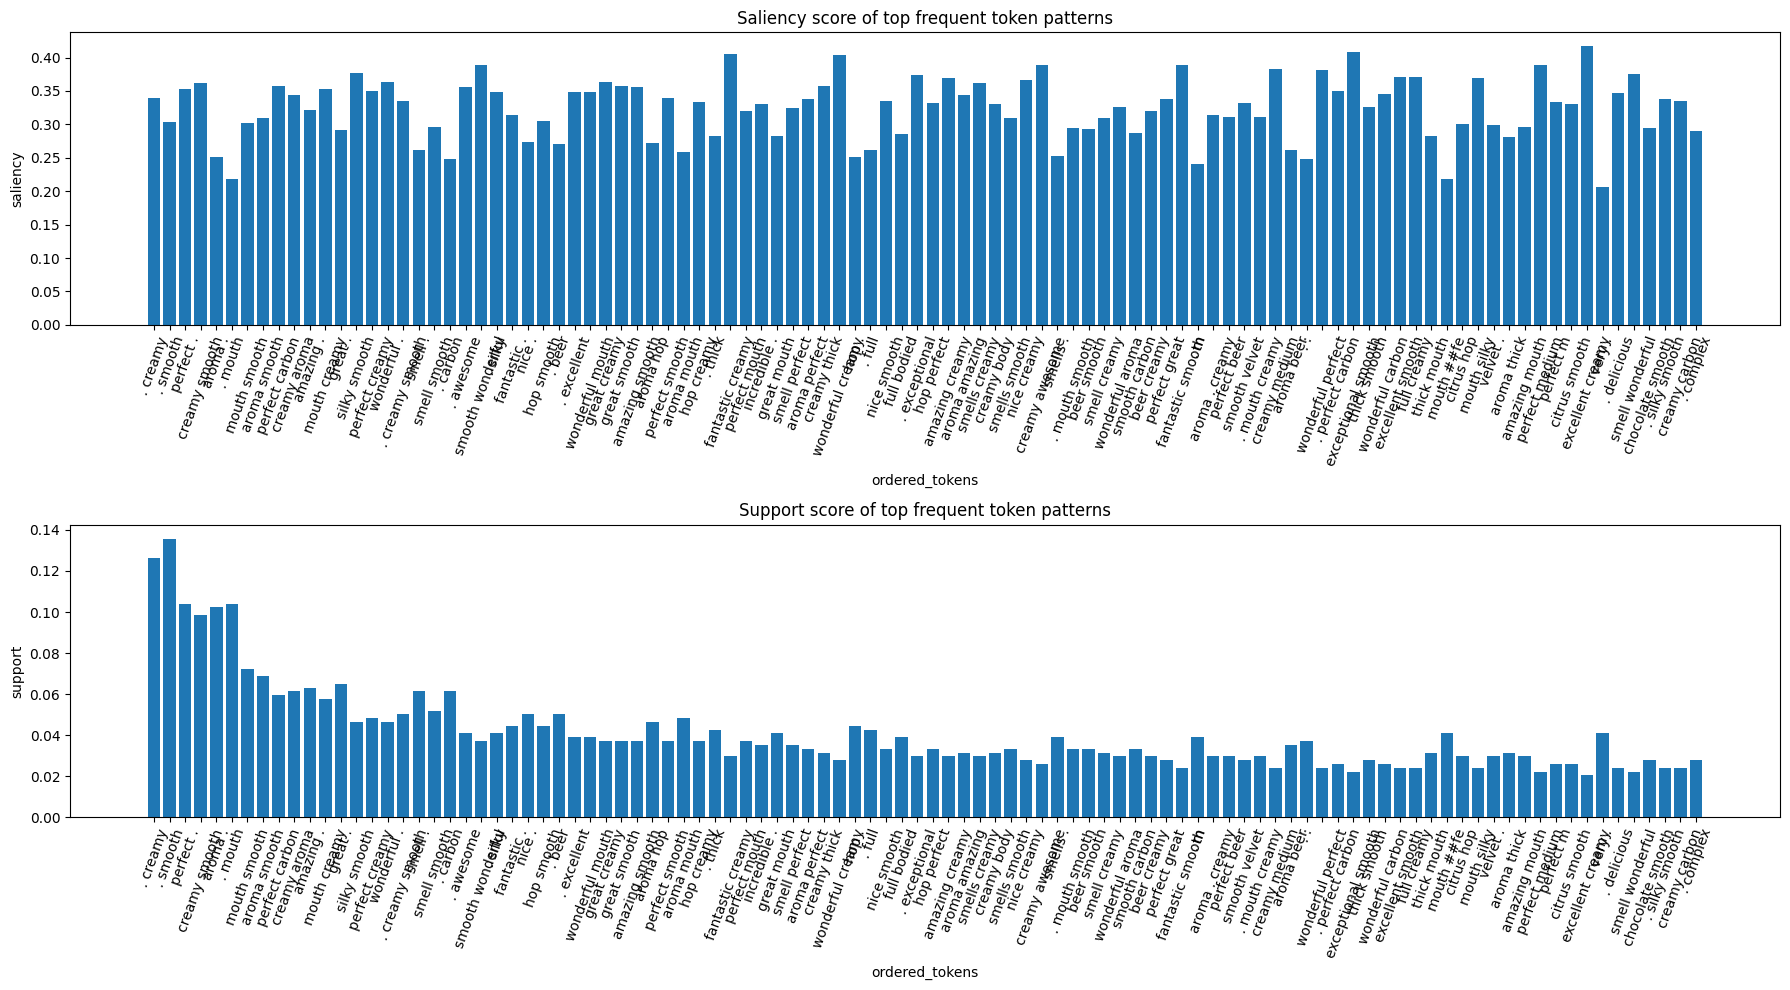

In [18]:
# Convert selected token lists to plot labels.
labels = two_grams["ordered_tokens"].apply(lambda x: " ".join(x))

fig, axes = plt.subplots(2, 1, figsize=(18,10))  # Two vertically stacked panels.

# Plot the selected patterns in the first panel.
axes[0].bar(labels, two_grams["saliency_score"])
axes[0].set_xlabel("ordered_tokens")
axes[0].set_ylabel("saliency")
axes[0].set_title("Saliency score of top frequent token patterns")
axes[0].tick_params(axis="x", rotation=70)

# Plot the second pattern metric.
axes[1].bar(labels, two_grams["support"])  # Second panel uses the corresponding pattern data.
axes[1].set_xlabel("ordered_tokens")
axes[1].set_ylabel("support")
axes[1].set_title("Support score of top frequent token patterns")
axes[1].tick_params(axis="x", rotation=70)

plt.tight_layout()
plt.show()

### Extract Token-Level Hidden States

The extraction function collects the selected pattern-token representations at specified encoder layers.

In [19]:
@torch.no_grad()
def extract_itemset_hidden_states(
    model,
    tokenizer,
    itemsets_token_ids, # Token-ID sequences for the mined patterns.
    device,
    layers=(11, 12),
    context_mode="isolated",     # Select isolated or templated model input.
    template_prefix="This beer is",
    batch_size=32,
    num_labels=4,
    pad_to_length=None,
):
    """
    Returns:
      out: dict layer_idx -> list[np.ndarray of shape (itemset_len, hidden_dim)]
      logits_out: np.ndarray [n_itemsets, num_labels]
    """

    model.eval()

    cls_id = tokenizer.cls_token_id
    sep_id = tokenizer.sep_token_id
    pad_id = tokenizer.pad_token_id if tokenizer.pad_token_id is not None else 0

    if context_mode == "isolated":
        base_ids = []
        token_start = 1
    elif context_mode == "template":
        base_ids = tokenizer(template_prefix, add_special_tokens=False).input_ids
        token_start = 1 + len(base_ids)
    else:
        raise ValueError("context_mode must be 'isolated' or 'template'")

    out = {L: [] for L in layers}
    logits_out = []

    for start in range(0, len(itemsets_token_ids), batch_size):
        batch_itemsets = itemsets_token_ids[start:start + batch_size]

        input_ids_list = []
        token_ranges = []

        for ids in batch_itemsets:
            ids = [int(t) for t in ids]

            full_ids = [cls_id] + base_ids + ids + [sep_id]
            input_ids_list.append(full_ids)

            # Locate the pattern-token positions in the model input.
            token_ranges.append((token_start, token_start + len(ids)))

        max_len = max(len(x) for x in input_ids_list)
        if pad_to_length is not None:
            if pad_to_length < max_len:
                raise ValueError("pad_to_length is shorter than an input sequence")
            max_len = pad_to_length

        padded_input_ids = []
        attention_masks = []
        token_type_ids = []

        for ids in input_ids_list:
            pad_len = max_len - len(ids)
            padded_input_ids.append(ids + [pad_id] * pad_len)
            attention_masks.append([1] * len(ids) + [0] * pad_len)
            token_type_ids.append([0] * max_len)

        input_ids = torch.tensor(padded_input_ids, dtype=torch.long, device=device)
        attention_mask = torch.tensor(attention_masks, dtype=torch.long, device=device)
        token_type_ids = torch.tensor(token_type_ids, dtype=torch.long, device=device)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            token_type_ids=token_type_ids,
            output_hidden_states=True,
            return_dict=True,
        )

        if hasattr(outputs, "logits"):
            logits_out.append(outputs.logits.detach().cpu().numpy())
        else:
            bsz = input_ids.shape[0]
            logits_out.append(np.full((bsz, num_labels), np.nan, dtype=float))

        hs = outputs.hidden_states

        for b_idx, (s, e) in enumerate(token_ranges):
            for L in layers:
                vecs = hs[L][b_idx, s:e, :].detach().cpu().numpy()   # Pattern-token representation shape: [n_tokens, hidden_size].
                out[L].append(vecs)

    logits_out = np.vstack(logits_out)

    return out, logits_out

### Extract Hidden States in Isolated and Templated Contexts

Patterns are processed by pretrained and fine-tuned BERT, both in isolation and after a fixed sentence prefix.

In [20]:
layers = (5, 8, 11, 12)
itemset_ids = two_grams["ordered_ids"].tolist()

# Extract pretrained representations.
pt_iso, pt_logits_iso = extract_itemset_hidden_states(
    pt_bert, tokenizer, itemset_ids, device, layers=layers, context_mode="isolated"
)
pt_tpl, pt_logits_tpl = extract_itemset_hidden_states(
    pt_bert, tokenizer, itemset_ids, device, layers=layers, context_mode="template"
)

# Extract fine-tuned representations.
ft_iso, ft_logits_iso = extract_itemset_hidden_states(
    ft_bert, tokenizer, itemset_ids, device, layers=layers, context_mode="isolated"
)
ft_tpl, ft_logits_tpl = extract_itemset_hidden_states(
    ft_bert, tokenizer, itemset_ids, device, layers=layers, context_mode="template"
)

### Add Hidden-State Representations to the DataFrame

In [21]:
for L in layers:
    two_grams[f"pt_iso_l{L}"] = list(pt_iso[L])
    two_grams[f"pt_tpl_l{L}"] = list(pt_tpl[L])
    two_grams[f"ft_iso_l{L}"] = list(ft_iso[L])
    two_grams[f"ft_tpl_l{L}"] = list(ft_tpl[L])

### Compare Pretrained and Fine-Tuned Layer-12 Representations

Mean-pooled representations are compared using cosine and Euclidean distances for each selected pattern.

In [22]:
def pool(x):
    x = np.asarray(x)
    return x.mean(axis=0) if x.ndim == 2 else x

def cos_shift(pt, ft):
    a = pool(pt)
    b = pool(ft)
    cos = np.dot(a,b)/(np.linalg.norm(a)*np.linalg.norm(b))
    return 1 - cos

def euc_dist(pt, ft):
    a = pool(pt)
    b = pool(ft)
    return np.linalg.norm(a - b)

layers = (5, 8, 11, 12)

top = two_grams.sort_values("support", ascending=False).head(30).copy()

for L in layers:
    top[f"cos_shift_iso_l{L}"] = [
        cos_shift(pt, ft) if pt is not None and ft is not None else None
        for pt, ft in zip(top[f"pt_iso_l{L}"], top[f"ft_iso_l{L}"])
    ]

    top[f"euc_iso_l{L}"] = [
        euc_dist(pt, ft) if pt is not None and ft is not None else None
        for pt, ft in zip(top[f"pt_iso_l{L}"], top[f"ft_iso_l{L}"])
    ]

    top[f"cos_shift_tpl_l{L}"] = [
        cos_shift(pt, ft) if pt is not None and ft is not None else None
        for pt, ft in zip(top[f"pt_tpl_l{L}"], top[f"ft_tpl_l{L}"])
    ]

    top[f"euc_tpl_l{L}"] = [
        euc_dist(pt, ft) if pt is not None and ft is not None else None
        for pt, ft in zip(top[f"pt_tpl_l{L}"], top[f"ft_tpl_l{L}"])
    ]

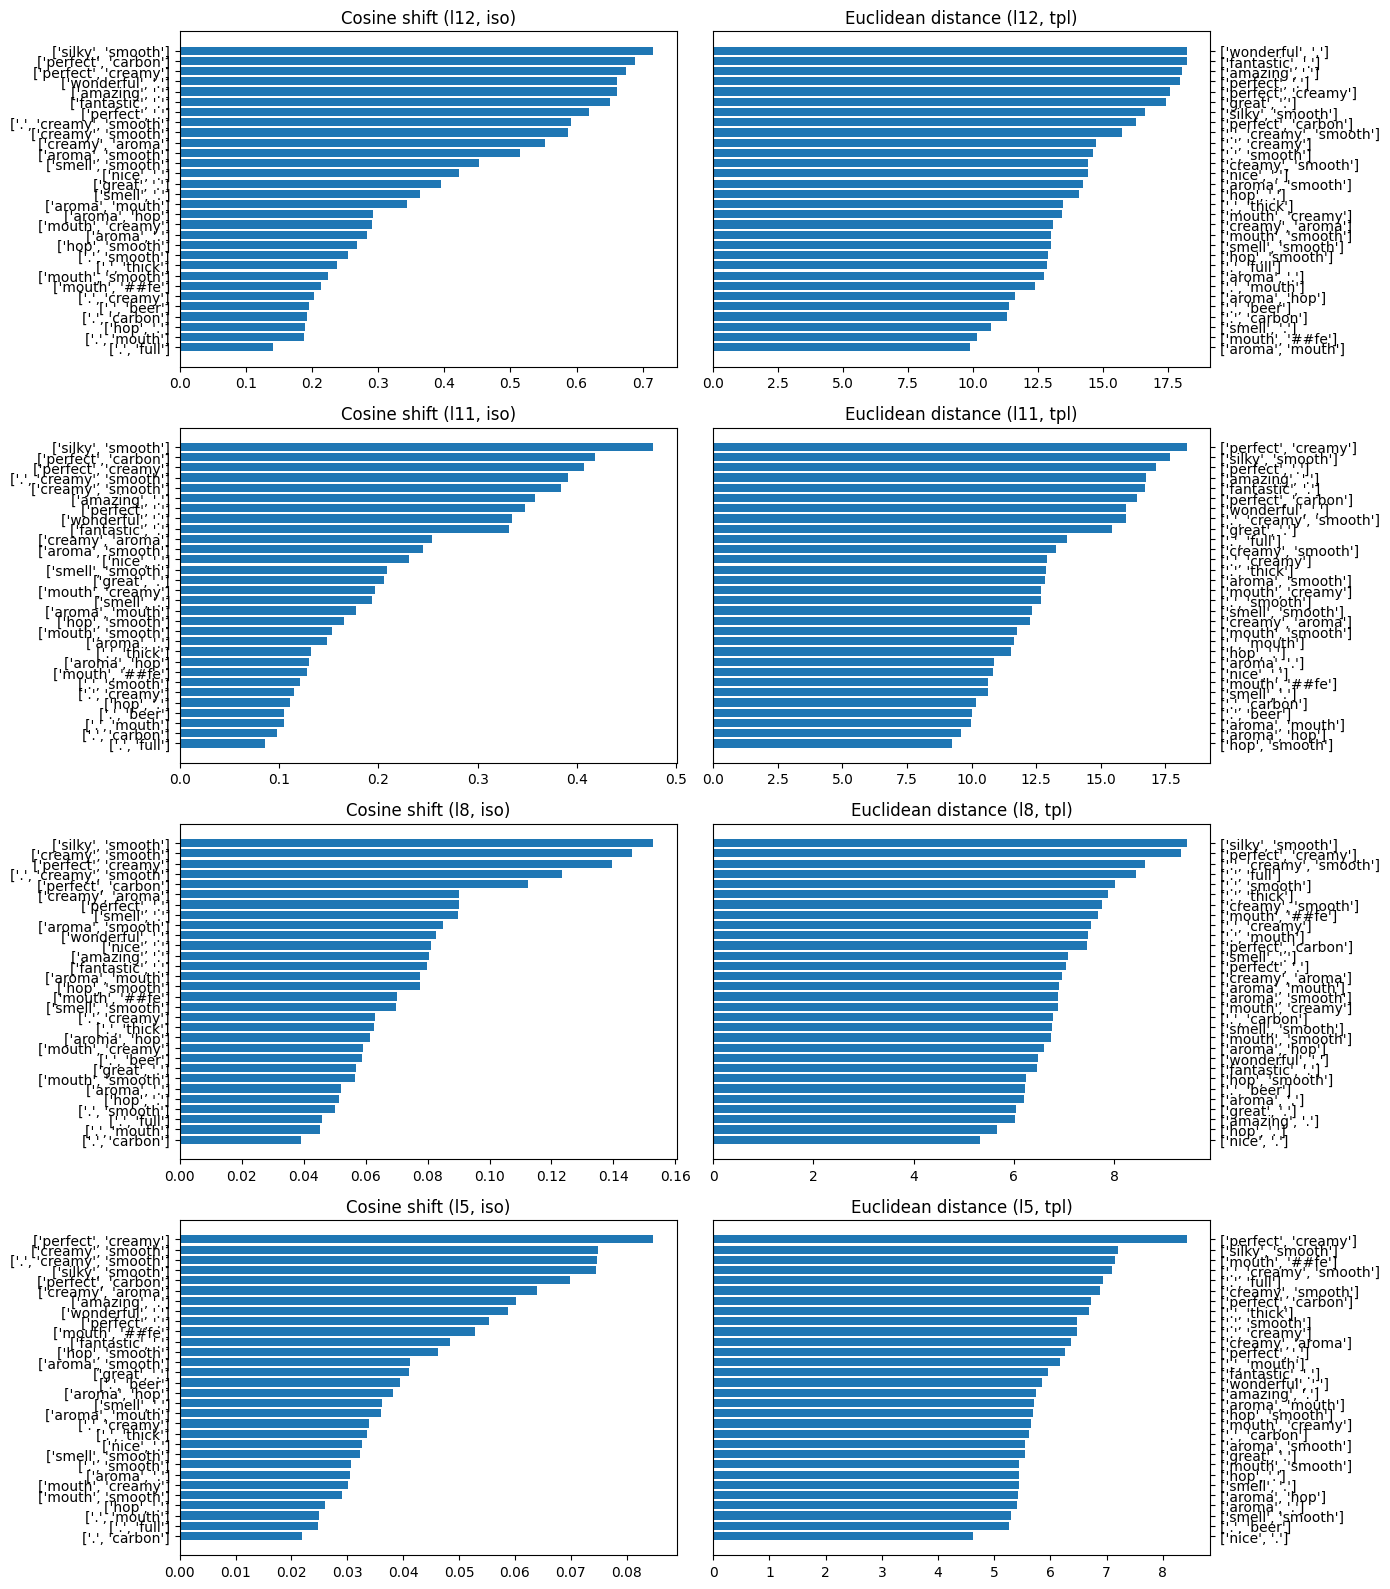

In [23]:
# Visualize representation-distance changes.

layers = (12,11,8,5)

fig, axes = plt.subplots(len(layers), 2, figsize=(14, 4 * len(layers)))
plt.subplots_adjust(wspace=0.6, hspace=0.4)

for i, L in enumerate(layers):
    # Cosine-distance panel.
    s1 = top.sort_values(f"cos_shift_iso_l{L}", ascending=False)
    axes[i, 0].barh(range(len(s1)), s1[f"cos_shift_iso_l{L}"])
    axes[i, 0].set_yticks(range(len(s1)))
    axes[i, 0].set_yticklabels(s1.ordered_tokens)
    axes[i, 0].set_title(f"Cosine shift (l{L}, iso)")
    axes[i, 0].invert_yaxis()

    # Euclidean-distance panel.
    s2 = top.sort_values(f"euc_tpl_l{L}", ascending=False)
    axes[i, 1].barh(range(len(s2)), s2[f"euc_tpl_l{L}"])
    axes[i, 1].set_yticks(range(len(s2)))
    axes[i, 1].set_yticklabels(s2.ordered_tokens)
    axes[i, 1].set_title(f"Euclidean distance (l{L}, tpl)")
    axes[i, 1].invert_yaxis()

    # Offset right-side labels to reduce overlap.
    axes[i, 1].yaxis.tick_right()

plt.tight_layout()

---

**Experiment 1 outputs.** Class-specific frequent patterns remain available in `freq_itemsets_by_class[0]` through `[3]` and in the four `freq_itemsets_class*_10` DataFrames. The next section compares neighbours of the mined patterns in pretrained and fine-tuned BERT.

---
## Experiment 2: Direct Representation Shifts and Nearest-Neighbour Changes

The analysis compares every mined single-token or multi-token pattern between pretrained BERT (PT) and fine-tuned BERT (FT) at layers **5, 8, 11, and 12**, for isolated (`iso`) and templated (`tpl`) input contexts. It uses mean pooling over the pattern tokens.

1. **Collect patterns.** Combine the mined patterns from all four predicted classes and deduplicate exact WordPiece token-ID sequences. Class-specific support, saliency, and score remain attached to each result row.
2. **Extract shared representations.** Run each unique sequence once through PT and FT BERT in each context. A fixed padded sequence length is used for all batches within a context; repeated patterns reuse the same cached vectors in every class.
3. **Measure direct representation movement.** For each pattern, layer, and context, calculate cosine distance (`direct_cosine_shift = 1 − cosine_similarity`) and Euclidean distance (`direct_euclidean_shift`) between its PT and FT hidden-state vectors.
4. **Define the neighbour vocabulary.** Use individual WordPiece tokens appearing in any mined pattern. Their PT and FT vectors are taken from the same shared representation cache.
5. **Find FT neighbours.** Select the **10 or 30 closest candidate tokens in FT space** using cosine similarity, excluding the pattern's constituent token IDs.
6. **Compare the same neighbours in PT.** Keep the FT-selected neighbour IDs fixed and calculate their distances to the pattern in both spaces.
7. **Summarize the changes.** Compute the mean absolute change in neighbour distances (`mean_abs_cosine_shift`, `mean_abs_euclidean_shift`) and the signed contraction (`mean_signed_cosine_contraction`, `mean_signed_euclidean_contraction`), where positive contraction means the neighbours are closer in FT than PT.
8. **Inspect DataFrames.** `nn_10_df` and `nn_30_df` contain all four classes, contexts, and layers. `direct_shift_df` contains one row per pattern, class, layer, and context without repeating the results for two neighbour counts. Checks confirm that identical token-ID sequences have identical neighbour results across classes.

**Interpretation:** Direct shift measures displacement of a pattern's own representation. Neighbour shift measures change in the pattern's relationships to specific FT-selected neighbours. These measures are not equivalent. Patterns mined by FP-Growth are unordered co-occurrences; their `ordered_ids` specify one observed sequence for representation extraction. Neither measure alone establishes causal shortcut reliance.


In [24]:
# Layers, contexts, and FT-neighbour counts used in Experiment 2.
NN_LAYERS = (5, 8, 11, 12)
NN_CONTEXTS = {"iso": "isolated", "tpl": "template"}
NN_K_VALUES = (10, 30)
NN_TEMPLATE_PREFIX = "This beer is"
NN_BATCH_SIZE = 32


def nn_extract_mean_states(model, pattern_ids, context, batch_size=NN_BATCH_SIZE):
    """Extract mean-pooled pattern-token vectors with a fixed input length."""
    if not pattern_ids:
        raise ValueError("Cannot extract embeddings for an empty list of patterns")

    hs, _ = extract_itemset_hidden_states(
        model=model,
        tokenizer=tokenizer,
        itemsets_token_ids=pattern_ids,
        device=device,
        layers=NN_LAYERS,
        context_mode=NN_CONTEXTS[context],
        template_prefix=NN_TEMPLATE_PREFIX,
        batch_size=batch_size,
        pad_to_length=NN_FIXED_PAD_LENGTH[context],
    )
    return {
        L: np.vstack([
            np.asarray(x, dtype=np.float32).mean(axis=0)
            for x in hs[L]
        ]).astype(np.float32)
        for L in NN_LAYERS
    }


def nn_normalize_rows(matrix):
    matrix = np.asarray(matrix, dtype=np.float32)
    return matrix / np.maximum(np.linalg.norm(matrix, axis=1, keepdims=True), 1e-12)


### Shared Representation Cache and Neighbour Vocabulary

The candidate vocabulary consists of WordPiece tokens occurring in the mined patterns. All unique pattern sequences and candidate singletons are extracted **once per model and context**, with identical padding across extraction batches. The shared cache guarantees that a token or pattern with the same ordered token IDs has the same PT/FT representation, regardless of the class in which it was mined. A small batch-size consistency check verifies deterministic extraction.


In [25]:
# Build the shared candidate-token pool across all predicted classes.
NN_TOKEN_IDS = sorted({
    int(token_id)
    for c in range(4)
    for ids in freq_itemsets_by_class[c]["ordered_ids"]
    for token_id in ids
})
if len(NN_TOKEN_IDS) < 2:
    raise ValueError("Need at least two mined token IDs to compute neighbours")
if len(NN_TOKEN_IDS) < max(NN_K_VALUES) + 4:
    print(f"Note: only {len(NN_TOKEN_IDS)} candidate tokens; some patterns may have fewer than 30 eligible neighbours.")

NN_TOKEN_LABELS = tokenizer.convert_ids_to_tokens(NN_TOKEN_IDS)
NN_TOKEN_IDS_ARRAY = np.asarray(NN_TOKEN_IDS, dtype=int)

# Each ordered token-ID sequence is encoded once, regardless of the number of classes containing it.
NN_PATTERN_KEYS = sorted({
    tuple(map(int, ids))
    for c in range(4)
    for ids in freq_itemsets_by_class[c]["ordered_ids"]
}.union({(tid,) for tid in NN_TOKEN_IDS}), key=lambda key: (len(key), key))
NN_PATTERN_INDEX = {key: i for i, key in enumerate(NN_PATTERN_KEYS)}
NN_TOKEN_INDICES = np.asarray([NN_PATTERN_INDEX[(tid,)] for tid in NN_TOKEN_IDS], dtype=int)
NN_PATTERN_LIST = [list(key) for key in NN_PATTERN_KEYS]

# A single padding length per context avoids dependence on other patterns in an extraction batch.
_max_pattern_len = max(map(len, NN_PATTERN_KEYS))
NN_FIXED_PAD_LENGTH = {
    "iso": 2 + _max_pattern_len,  # [CLS] + pattern + [SEP]
    "tpl": 2 + len(tokenizer(NN_TEMPLATE_PREFIX, add_special_tokens=False).input_ids) + _max_pattern_len,
}

# Shared [n_unique_patterns, hidden_size] matrices for each model, context, and layer.
nn_pattern_vectors = {}
for context in NN_CONTEXTS:
    for model_type, model in (("pt", pt_bert), ("ft", ft_bert)):
        print(f"Encoding {len(NN_PATTERN_KEYS)} unique patterns: {model_type}, {context}")
        states = nn_extract_mean_states(model, NN_PATTERN_LIST, context)
        for L in NN_LAYERS:
            nn_pattern_vectors[(model_type, context, L)] = states[L]

# Check consistency of a small fixed sample across extraction batch sizes.
_check_keys = [(tid,) for tid in NN_TOKEN_IDS[:min(3, len(NN_TOKEN_IDS))]]
for context in NN_CONTEXTS:
    for model_type, model in (("pt", pt_bert), ("ft", ft_bert)):
        single = nn_extract_mean_states(model, [list(k) for k in _check_keys], context, batch_size=1)
        for L in NN_LAYERS:
            reference = nn_pattern_vectors[(model_type, context, L)][
                [NN_PATTERN_INDEX[k] for k in _check_keys]
            ]
            max_difference = float(np.max(np.abs(reference - single[L])))
            if max_difference > 1e-3:
                raise RuntimeError(
                    f"Inconsistent hidden states across batch sizes for {model_type}/{context}/L{L}: "
                    f"max absolute difference = {max_difference:.5g}"
                )

# Reuse the same candidate vectors as the pattern vectors for single-token patterns.
NN_GEOMETRY = {}
for context in NN_CONTEXTS:
    for L in NN_LAYERS:
        pt_all = nn_pattern_vectors[("pt", context, L)]
        ft_all = nn_pattern_vectors[("ft", context, L)]
        pt_norm = nn_normalize_rows(pt_all)
        ft_norm = nn_normalize_rows(ft_all)
        ft_candidate_norm = ft_norm[NN_TOKEN_INDICES]
        NN_GEOMETRY[(context, L)] = {
            "pt_all": pt_all,
            "ft_all": ft_all,
            "pt_norm": pt_norm,
            "ft_norm": ft_norm,
            "pt_candidates": pt_all[NN_TOKEN_INDICES],
            "ft_candidates": ft_all[NN_TOKEN_INDICES],
            "pt_candidate_norm": pt_norm[NN_TOKEN_INDICES],
            "ft_candidate_norm": ft_candidate_norm,
            "ft_similarities": ft_norm @ ft_candidate_norm.T,
            "direct_cosine": np.maximum(0.0, 1.0 - np.sum(pt_norm * ft_norm, axis=1)),
            "direct_euclidean": np.linalg.norm(pt_all - ft_all, axis=1),
        }

print("Shared neighbour vocabulary size:", len(NN_TOKEN_IDS))
print("Unique pattern sequences:", len(NN_PATTERN_KEYS))
print("Batch-size representation consistency: passed")


Encoding 1735 unique patterns: pt, iso
Encoding 1735 unique patterns: ft, iso
Encoding 1735 unique patterns: pt, tpl
Encoding 1735 unique patterns: ft, tpl
Shared neighbour vocabulary size: 292
Unique pattern sequences: 1735
Batch-size representation consistency: passed


### Direct Pattern Shift and Fine-Tuned Neighbour Comparison

Each pattern's own PT–FT cosine and Euclidean distances are computed directly from its cached vectors. The same pattern is then compared to the NN-10 and NN-30 tokens selected in FT space. PT distances are measured to those exact neighbour IDs. Repeated token-ID sequences across predicted classes share identical vectors, neighbour identities, and distance metrics.


In [26]:
def nn_class_distance_comparison(predicted_class):
    """Measure direct pattern shifts and FT-neighbour distance changes for one class."""
    source = freq_itemsets_by_class[predicted_class].reset_index(drop=True)
    if source.empty:
        return pd.DataFrame()

    pattern_keys = [tuple(map(int, ids)) for ids in source["ordered_ids"]]
    rows = []

    for context in NN_CONTEXTS:
        for L in NN_LAYERS:
            geom = NN_GEOMETRY[(context, L)]
            for i, key in enumerate(pattern_keys):
                pattern_idx = NN_PATTERN_INDEX[key]
                similarities = geom["ft_similarities"][pattern_idx].copy()
                # Exclude the anchor's constituent WordPiece IDs.
                similarities[np.isin(NN_TOKEN_IDS_ARRAY, key)] = -np.inf
                n_select = min(max(NN_K_VALUES), int(np.isfinite(similarities).sum()))
                if not n_select:
                    continue
                candidate_indices = np.argsort(similarities)[-n_select:][::-1]

                ft_query = geom["ft_all"][pattern_idx]
                pt_query = geom["pt_all"][pattern_idx]
                ft_query_norm = geom["ft_norm"][pattern_idx]
                pt_query_norm = geom["pt_norm"][pattern_idx]

                ft_cos_dist = np.maximum(
                    0.0, 1.0 - geom["ft_candidate_norm"][candidate_indices] @ ft_query_norm
                )
                pt_cos_dist = np.maximum(
                    0.0, 1.0 - geom["pt_candidate_norm"][candidate_indices] @ pt_query_norm
                )
                ft_euc_dist = np.linalg.norm(
                    geom["ft_candidates"][candidate_indices] - ft_query, axis=1
                )
                pt_euc_dist = np.linalg.norm(
                    geom["pt_candidates"][candidate_indices] - pt_query, axis=1
                )

                for k in NN_K_VALUES:
                    n = min(k, n_select)
                    cos_ft, cos_pt = ft_cos_dist[:n], pt_cos_dist[:n]
                    euc_ft, euc_pt = ft_euc_dist[:n], pt_euc_dist[:n]
                    cos_signed = cos_pt - cos_ft
                    euc_signed = euc_pt - euc_ft

                    rows.append({
                        "predicted_class": predicted_class,
                        "rating": ID_TO_RATING[predicted_class],
                        "pattern_text": " ".join(source.iloc[i]["ordered_tokens"]),
                        "ordered_tokens": list(source.iloc[i]["ordered_tokens"]),
                        "ordered_ids": list(key),
                        "length": int(source.iloc[i]["length"]),
                        "support": float(source.iloc[i]["support"]),
                        "support_count": int(source.iloc[i]["support_count"]),
                        "saliency_score": float(source.iloc[i]["saliency_score"]),
                        "score": float(source.iloc[i]["score"]),
                        "layer": L,
                        "context": context,
                        "k": k,
                        "actual_k": n,
                        "direct_cosine_shift": float(geom["direct_cosine"][pattern_idx]),
                        "direct_euclidean_shift": float(geom["direct_euclidean"][pattern_idx]),
                        "ft_nn_token_ids": NN_TOKEN_IDS_ARRAY[candidate_indices[:n]].tolist(),
                        "ft_nn_tokens": [NN_TOKEN_LABELS[j] for j in candidate_indices[:n]],
                        "ft_nn_cosine_distances": cos_ft.tolist(),
                        "pt_same_nn_cosine_distances": cos_pt.tolist(),
                        "signed_cosine_contractions": cos_signed.tolist(),
                        "absolute_cosine_shifts": np.abs(cos_signed).tolist(),
                        "mean_abs_cosine_shift": float(np.abs(cos_signed).mean()),
                        "mean_signed_cosine_contraction": float(cos_signed.mean()),
                        "ft_nn_euclidean_distances": euc_ft.tolist(),
                        "pt_same_nn_euclidean_distances": euc_pt.tolist(),
                        "signed_euclidean_contractions": euc_signed.tolist(),
                        "absolute_euclidean_shifts": np.abs(euc_signed).tolist(),
                        "mean_abs_euclidean_shift": float(np.abs(euc_signed).mean()),
                        "mean_signed_euclidean_contraction": float(euc_signed.mean()),
                    })

    return pd.DataFrame(rows)


In [27]:
# Compute the FT-selected-neighbour comparison for each predicted class.
_nn_class_results = []
for c in range(4):
    print(f"Computing neighbour comparisons for class {c} (palate {ID_TO_RATING[c]:.1f})")
    _nn_class_results.append(nn_class_distance_comparison(c))

nn_shift_df = pd.concat(_nn_class_results, ignore_index=True)
if nn_shift_df.empty:
    raise ValueError("No neighbour comparisons were produced")

# Identical ordered WordPiece sequences must have identical geometric results across classes.
_check_df = nn_shift_df.copy()
_check_df["_pattern_key"] = _check_df["ordered_ids"].map(tuple)
_geom_columns = [
    "direct_cosine_shift", "direct_euclidean_shift",
    "mean_abs_cosine_shift", "mean_abs_euclidean_shift",
    "mean_signed_cosine_contraction", "mean_signed_euclidean_contraction",
]
_repeated_groups = 0
for _, group in _check_df.groupby(["_pattern_key", "context", "layer", "k"]):
    if len(group) < 2:
        continue
    _repeated_groups += 1
    if len({tuple(ids) for ids in group["ft_nn_token_ids"]}) != 1:
        raise AssertionError("Different FT neighbour IDs for the same pattern, layer, and context")
    values = group[_geom_columns].to_numpy(dtype=float)
    if not np.allclose(values, values[0], rtol=1e-6, atol=1e-6):
        raise AssertionError("Different shift metrics for the same pattern, layer, and context")
print(f"Cross-class neighbour consistency: passed ({_repeated_groups} repeated-pattern groups checked)")

nn_10_df = nn_shift_df.loc[nn_shift_df["k"] == 10].copy()
nn_30_df = nn_shift_df.loc[nn_shift_df["k"] == 30].copy()

# Direct shifts contain no NN-k dependence.
direct_shift_df = nn_10_df.drop(columns=[
    "k", "actual_k", "ft_nn_token_ids", "ft_nn_tokens", "ft_nn_cosine_distances",
    "pt_same_nn_cosine_distances", "signed_cosine_contractions", "absolute_cosine_shifts",
    "mean_abs_cosine_shift", "mean_signed_cosine_contraction", "ft_nn_euclidean_distances",
    "pt_same_nn_euclidean_distances", "signed_euclidean_contractions",
    "absolute_euclidean_shifts", "mean_abs_euclidean_shift",
    "mean_signed_euclidean_contraction",
]).copy()

nn_class0_10_df = nn_10_df.loc[nn_10_df["predicted_class"] == 0].copy()
nn_class1_10_df = nn_10_df.loc[nn_10_df["predicted_class"] == 1].copy()
nn_class2_10_df = nn_10_df.loc[nn_10_df["predicted_class"] == 2].copy()
nn_class3_10_df = nn_10_df.loc[nn_10_df["predicted_class"] == 3].copy()

nn_class0_30_df = nn_30_df.loc[nn_30_df["predicted_class"] == 0].copy()
nn_class1_30_df = nn_30_df.loc[nn_30_df["predicted_class"] == 1].copy()
nn_class2_30_df = nn_30_df.loc[nn_30_df["predicted_class"] == 2].copy()
nn_class3_30_df = nn_30_df.loc[nn_30_df["predicted_class"] == 3].copy()

print("Result counts by predicted class, context, layer, and neighbour count:")
print(nn_shift_df.groupby(["predicted_class", "context", "layer", "k"]).size().to_string())


Computing neighbour comparisons for class 0 (palate 0.4)
Computing neighbour comparisons for class 1 (palate 0.6)
Computing neighbour comparisons for class 2 (palate 0.8)
Computing neighbour comparisons for class 3 (palate 1.0)
Cross-class neighbour consistency: passed (7072 repeated-pattern groups checked)
Result counts by predicted class, context, layer, and neighbour count:
predicted_class  context  layer  k 
0                iso      5      10    325
                                 30    325
                          8      10    325
                                 30    325
                          11     10    325
                                 30    325
                          12     10    325
                                 30    325
                 tpl      5      10    325
                                 30    325
                          8      10    325
                                 30    325
                          11     10    325
                         

### Nearest-Neighbour and Direct-Shift Results

`nn_10_df` and `nn_30_df` contain the FT-neighbour comparison for 10 and 30 neighbours, respectively, for each predicted class, context, and layer. Both now also include **`direct_cosine_shift`** and **`direct_euclidean_shift`**, which compare the pattern's own PT and FT representations without involving neighbours.

`direct_shift_df` contains one row per class, pattern, context, and layer, without the duplicate NN-10/NN-30 measurements. The four `nn_class*_10_df` and four `nn_class*_30_df` DataFrames remain available for class-specific inspection.

- **Direct shift:** `direct_cosine_shift`, `direct_euclidean_shift`.
- **FT-selected neighbour shift:** `mean_abs_cosine_shift`, `mean_abs_euclidean_shift`.
- **Signed neighbour contraction:** `mean_signed_cosine_contraction`, `mean_signed_euclidean_contraction` (positive = neighbours closer in FT).

When comparing patterns across predicted classes, use the same layer and context. Equal ordered WordPiece token-ID sequences produce identical geometric measurements, although their class-specific support and saliency can differ.


In [28]:
# Example: top 30 shifted patterns for predicted class 3 at layer 12 (templated, NN-30).
nn_class3_30_df.query("layer == 12 and context == 'tpl'").sort_values(
    "mean_abs_cosine_shift", ascending=False
)[[
    "pattern_text", "length", "support", "saliency_score", "score",
    "mean_abs_cosine_shift", "mean_abs_euclidean_shift",
    "mean_signed_cosine_contraction", "mean_signed_euclidean_contraction",
    "ft_nn_tokens", "actual_k",
]].head(30)


,pattern_text,length,support,saliency_score,score,mean_abs_cosine_shift,mean_abs_euclidean_shift,mean_signed_cosine_contraction,mean_signed_euclidean_contraction,ft_nn_tokens,actual_k
38063,citrus .,2,0.024164,0.296846,0.007173,0.344520,2.300931,0.344520,2.300931,"[crisp, wheat, tropical, pine, moderate, pleas...",30
37997,stout .,2,0.024164,0.289690,0.007000,0.333780,1.921004,0.333780,1.921004,"[moderate, solid, crisp, medium, mild, roasted...",30
38357,hop .,2,0.044610,0.251870,0.011236,0.333644,2.354770,0.333644,2.354770,"[roasted, crisp, citrus, wheat, yeast, corn, s...",30
37945,good .,2,0.026022,0.231479,0.006024,0.322233,2.812524,0.322233,2.812524,"[nice, fine, pleasant, strong, smooth, clean, ...",30
38545,floral .,2,0.018587,0.253569,0.004713,0.319000,1.580509,0.319000,1.580509,"[pleasant, dense, crisp, moderate, wheat, juic...",30
38131,exceptional perfect,2,0.011152,0.348724,0.003889,0.272535,6.376853,-0.209079,-5.705554,"[incredible, amazing, superb, wonderful, fanta...",30
38243,sweet .,2,0.014870,0.229709,0.003416,0.268339,1.873238,0.268339,1.873238,"[pleasant, good, juicy, crisp, dense, solid, f...",30
38655,hazy .,2,0.018587,0.248409,0.004617,0.264621,0.953004,0.264621,0.865835,"[faint, lacking, watery, thin, weak, stale, di...",30
38373,aroma hop .,3,0.020446,0.247452,0.005059,0.259593,0.836133,0.259593,0.804506,"[crisp, solid, dense, strong, thick, moderate,...",30
38503,amazing perfect,2,0.018587,0.349363,0.006494,0.258644,6.175740,-0.206422,-5.750964,"[incredible, wonderful, fantastic, superb, exc...",30


In [29]:
# Example: top 30 shifted single-token patterns for class 0 at layer 5 (isolated, NN-10).
nn_class0_10_df.query("layer == 5 and context == 'iso' and length == 1").sort_values(
    "mean_abs_euclidean_shift", ascending=False
)[[
    "pattern_text", "length", "support", "saliency_score", "score",
    "mean_abs_cosine_shift", "mean_abs_euclidean_shift",
    "mean_signed_cosine_contraction", "mean_signed_euclidean_contraction",
    "ft_nn_tokens", "actual_k",
]].head(30)


,pattern_text,length,support,saliency_score,score,mean_abs_cosine_shift,mean_abs_euclidean_shift,mean_signed_cosine_contraction,mean_signed_euclidean_contraction,ft_nn_tokens,actual_k
94,grassy,1,0.023973,0.266885,0.006398,0.053247,1.499802,0.053247,1.499802,"[##ngen, beige, floral, ##sty, ##bbly, hazy, n...",10
16,good,1,0.085616,0.274251,0.023480,0.036633,1.138782,-0.036633,-1.138782,"[bad, nice, excellent, great, wonderful, lovel...",10
128,##unk,1,0.051370,0.269887,0.013864,0.024681,0.864469,0.024681,0.864469,"[##py, ##zzy, ##helm, ##mel, ##bbly, ##oth, ##...",10
70,##el,1,0.023973,0.172820,0.004143,0.032153,0.860985,0.032153,0.860985,"[##mel, ##ger, ##zzy, ##py, ##fe, ##helm, ##bb...",10
86,terrible,1,0.023973,0.393219,0.009426,0.026353,0.846694,-0.025425,-0.842873,"[wonderful, bad, incredible, brilliant, disapp...",10
198,strange,1,0.020548,0.311652,0.006404,0.027503,0.845930,-0.027503,-0.845930,"[odd, interesting, nice, terrible, unique, ama...",10
156,##zzy,1,0.037671,0.346537,0.013054,0.023251,0.840151,0.023251,0.840151,"[##bbly, ##py, ##helm, ##unk, ##mel, ##fe, ##s...",10
122,##fe,1,0.034247,0.180649,0.006187,0.024863,0.832074,0.024863,0.832074,"[##zzy, ##py, ##helm, ##bbly, ##unk, ##mel, ##...",10
28,thick,1,0.044521,0.325916,0.014510,0.023475,0.827971,-0.023475,-0.827971,"[thicker, thin, massive, dense, huge, cheap, d...",10
58,drink,1,0.027397,0.249873,0.006846,0.031903,0.800153,0.031903,0.800153,"[drinks, beer, coffee, alcohol, glass, feel, b...",10


In [30]:
# Example: class 3 multi-token patterns ranked by signed cosine contraction (NN-30).
nn_class3_30_df.query("layer == 12 and context == 'tpl' and length > 1").sort_values(
    "mean_signed_cosine_contraction", ascending=False
)[[
    "pattern_text", "length", "support", "saliency_score", "score",
    "mean_abs_cosine_shift", "mean_signed_cosine_contraction",
    "ft_nn_tokens", "actual_k",
]].head(30)


,pattern_text,length,support,saliency_score,score,mean_abs_cosine_shift,mean_signed_cosine_contraction,ft_nn_tokens,actual_k
38063,citrus .,2,0.024164,0.296846,0.007173,0.344520,0.344520,"[crisp, wheat, tropical, pine, moderate, pleas...",30
37997,stout .,2,0.024164,0.289690,0.007000,0.333780,0.333780,"[moderate, solid, crisp, medium, mild, roasted...",30
38357,hop .,2,0.044610,0.251870,0.011236,0.333644,0.333644,"[roasted, crisp, citrus, wheat, yeast, corn, s...",30
37945,good .,2,0.026022,0.231479,0.006024,0.322233,0.322233,"[nice, fine, pleasant, strong, smooth, clean, ...",30
38545,floral .,2,0.018587,0.253569,0.004713,0.319000,0.319000,"[pleasant, dense, crisp, moderate, wheat, juic...",30
38243,sweet .,2,0.014870,0.229709,0.003416,0.268339,0.268339,"[pleasant, good, juicy, crisp, dense, solid, f...",30
38655,hazy .,2,0.018587,0.248409,0.004617,0.264621,0.264621,"[faint, lacking, watery, thin, weak, stale, di...",30
38373,aroma hop .,3,0.020446,0.247452,0.005059,0.259593,0.259593,"[crisp, solid, dense, strong, thick, moderate,...",30
38075,citrus aroma .,3,0.013011,0.290600,0.003781,0.248104,0.248104,"[good, pleasant, crisp, juicy, strong, dense, ...",30
37813,lace .,2,0.018587,0.230926,0.004292,0.246784,0.246784,"[hop, texture, chew, aroma, mal, cinnamon, cor...",30


### Inspect Direct Shifts by Predicted Class

The direct shift rankings do not depend on the number of neighbours. Filter `direct_shift_df` by predicted class, layer, and context to identify the most changed token or token-group representations. The FP-Growth support and saliency columns are preserved for comparison.


In [31]:
# Highest direct cosine shifts for predicted class 3, layer 11, templated input.
direct_shift_df.query("predicted_class == 3 and layer == 11 and context == 'tpl'").sort_values(
    "direct_cosine_shift", ascending=False
)[["pattern_text", "length", "support", "saliency_score", "score", "direct_cosine_shift", "direct_euclidean_shift"]].head(30)


,pattern_text,length,support,saliency_score,score,direct_cosine_shift,direct_euclidean_shift
37238,silky perfect,2,0.011152,0.432259,0.004821,0.615785,21.159658
36388,perfect .,2,0.104089,0.352886,0.036732,0.554293,17.151352
36452,perfect great .,3,0.013011,0.320482,0.004170,0.551453,17.900080
36714,chocolate perfect,2,0.011152,0.362199,0.004039,0.550001,18.687294
36692,exceptional perfect,2,0.011152,0.348724,0.003889,0.549726,19.878365
36880,outstanding .,2,0.014870,0.361538,0.005376,0.548615,17.310730
37250,. mouth silky smooth,4,0.011152,0.325570,0.003631,0.546018,20.113108
36480,fantastic perfect,2,0.013011,0.320083,0.004165,0.544206,19.420856
37064,amazing perfect,2,0.018587,0.349363,0.006494,0.539714,19.546164
36468,fantastic .,2,0.044610,0.313988,0.014007,0.533067,16.723303


**Experiment 2 outputs.** `nn_10_df` and `nn_30_df` contain all nearest-neighbour comparisons. Class-specific results are available in `nn_class0_10_df` through `nn_class3_10_df` and `nn_class0_30_df` through `nn_class3_30_df`. The tables retain the fine-tuned neighbour IDs, their token labels, and distances for those same neighbour pairs in pretrained and fine-tuned BERT.

In [32]:
# nn_10_df.to_csv("nn_10_results_correlation.csv", index=False)
# nn_30_df.to_csv("nn_30_results_correlation.csv", index=False)

In [33]:

# Top 30 most strongly shifted patterns at layer 12
# Repeat for classes 0/3 and NN-10/NN-30.

top30_neighborhood_shifts = {}

for class_id in (0, 3):
    for k in (10, 30):
        result = (
            nn_shift_df
            .query(
                "predicted_class == @class_id "
                "and layer == 12 "
                "and k == @k "
                "and context == 'tpl'"
            )
            .sort_values("mean_abs_cosine_shift", ascending=False)
            [[
                "pattern_text",
                "length",
                "support",
                "saliency_score",
                "score",
                "mean_abs_cosine_shift",
                "mean_abs_euclidean_shift",
                "mean_signed_cosine_contraction",
                "ft_nn_tokens",
            ]]
            .head(30)
            .reset_index(drop=True)
        )

        top30_neighborhood_shifts[(class_id, k)] = result

        print(f"Palate {ID_TO_RATING[class_id]:.1f} | NN-{k}")
        display(result)


Palate 0.4 | NN-10


,pattern_text,length,support,saliency_score,score,mean_abs_cosine_shift,mean_abs_euclidean_shift,mean_signed_cosine_contraction,ft_nn_tokens
0,decent .,2,0.034247,0.293016,0.010035,0.358189,3.459617,0.358189,"[fine, good, nice, moderate, pleasant, crisp, ..."
1,great .,2,0.020548,0.346638,0.007123,0.344036,4.667437,0.344036,"[awesome, fantastic, brilliant, gorgeous, amaz..."
2,hop .,2,0.041096,0.232443,0.009552,0.343577,2.690552,0.343577,"[roasted, crisp, citrus, wheat, yeast, corn, s..."
3,creamy .,2,0.041096,0.306534,0.012597,0.336150,2.920010,0.336150,"[pleasant, smooth, strong, refreshing, nice, g..."
4,grain .,2,0.020548,0.268024,0.005507,0.331787,2.415237,0.331787,"[wheat, corn, roasted, spices, yeast, grains, ..."
5,good .,2,0.037671,0.267147,0.010064,0.331134,3.718892,0.331134,"[nice, fine, pleasant, strong, smooth, clean, ..."
6,smooth .,2,0.023973,0.344647,0.008262,0.316120,3.436026,0.316120,"[creamy, pleasant, nice, strong, good, crisp, ..."
7,sk ##unk .,3,0.020548,0.298361,0.006131,0.295610,1.213673,0.295610,"[terrible, watery, poor, strange, thin, stale,..."
8,faint .,2,0.051370,0.316581,0.016263,0.291734,1.614326,0.291734,"[thin, weak, watery, poor, disappointing, lack..."
9,too thin .,3,0.030822,0.323242,0.009963,0.228235,0.748516,0.228235,"[terrible, strange, weak, watery, nothing, bad..."


Palate 0.4 | NN-30


,pattern_text,length,support,saliency_score,score,mean_abs_cosine_shift,mean_abs_euclidean_shift,mean_signed_cosine_contraction,ft_nn_tokens
0,decent .,2,0.034247,0.293016,0.010035,0.366222,3.015146,0.366222,"[fine, good, nice, moderate, pleasant, crisp, ..."
1,hop .,2,0.041096,0.232443,0.009552,0.333644,2.354770,0.333644,"[roasted, crisp, citrus, wheat, yeast, corn, s..."
2,good .,2,0.037671,0.267147,0.010064,0.322233,2.812524,0.322233,"[nice, fine, pleasant, strong, smooth, clean, ..."
3,grain .,2,0.020548,0.268024,0.005507,0.318661,2.010406,0.318661,"[wheat, corn, roasted, spices, yeast, grains, ..."
4,creamy .,2,0.041096,0.306534,0.012597,0.300234,1.831564,0.300234,"[pleasant, smooth, strong, refreshing, nice, g..."
5,smooth .,2,0.023973,0.344647,0.008262,0.294863,2.371629,0.294863,"[creamy, pleasant, nice, strong, good, crisp, ..."
6,faint .,2,0.051370,0.316581,0.016263,0.241798,0.936325,0.241798,"[thin, weak, watery, poor, disappointing, lack..."
7,great .,2,0.020548,0.346638,0.007123,0.225807,3.386154,0.207436,"[awesome, fantastic, brilliant, gorgeous, amaz..."
8,sk ##unk .,3,0.020548,0.298361,0.006131,0.199828,1.489465,0.199828,"[terrible, watery, poor, strange, thin, stale,..."
9,##fe ##el,2,0.020548,0.181031,0.003720,0.174982,0.927558,0.174982,"[well, mouth, smelled, lingering, smelling, ar..."


Palate 1.0 | NN-10


,pattern_text,length,support,saliency_score,score,mean_abs_cosine_shift,mean_abs_euclidean_shift,mean_signed_cosine_contraction,ft_nn_tokens
0,huge .,2,0.013011,0.341838,0.004448,0.379744,4.996534,0.379744,"[incredible, amazing, fantastic, brilliant, aw..."
1,incredible .,2,0.035316,0.330926,0.011687,0.375192,5.340828,0.375192,"[amazing, perfect, fantastic, superb, wonderfu..."
2,fantastic .,2,0.044610,0.313988,0.014007,0.370715,5.514317,0.370715,"[amazing, incredible, perfect, brilliant, wond..."
3,perfect .,2,0.104089,0.352886,0.036732,0.370220,4.847840,0.370220,"[incredible, amazing, fantastic, gorgeous, won..."
4,citrus .,2,0.024164,0.296846,0.007173,0.360951,2.839170,0.360951,"[crisp, wheat, tropical, pine, moderate, pleas..."
5,outstanding .,2,0.014870,0.361538,0.005376,0.360844,4.861477,0.360844,"[exceptional, superb, incredible, amazing, bri..."
6,amazing .,2,0.063197,0.321267,0.020303,0.355001,5.401166,0.355001,"[incredible, perfect, fantastic, wonderful, su..."
7,stout .,2,0.024164,0.289690,0.007000,0.354360,2.560883,0.354360,"[moderate, solid, crisp, medium, mild, roasted..."
8,wonderful .,2,0.046468,0.362935,0.016865,0.353780,5.301795,0.353780,"[amazing, fantastic, incredible, perfect, supe..."
9,great .,2,0.065056,0.291588,0.018969,0.344036,4.667437,0.344036,"[awesome, fantastic, brilliant, gorgeous, amaz..."


Palate 1.0 | NN-30


,pattern_text,length,support,saliency_score,score,mean_abs_cosine_shift,mean_abs_euclidean_shift,mean_signed_cosine_contraction,ft_nn_tokens
0,citrus .,2,0.024164,0.296846,0.007173,0.344520,2.300931,0.344520,"[crisp, wheat, tropical, pine, moderate, pleas..."
1,stout .,2,0.024164,0.289690,0.007000,0.333780,1.921004,0.333780,"[moderate, solid, crisp, medium, mild, roasted..."
2,hop .,2,0.044610,0.251870,0.011236,0.333644,2.354770,0.333644,"[roasted, crisp, citrus, wheat, yeast, corn, s..."
3,good .,2,0.026022,0.231479,0.006024,0.322233,2.812524,0.322233,"[nice, fine, pleasant, strong, smooth, clean, ..."
4,floral .,2,0.018587,0.253569,0.004713,0.319000,1.580509,0.319000,"[pleasant, dense, crisp, moderate, wheat, juic..."
5,exceptional perfect,2,0.011152,0.348724,0.003889,0.272535,6.376853,-0.209079,"[incredible, amazing, superb, wonderful, fanta..."
6,sweet .,2,0.014870,0.229709,0.003416,0.268339,1.873238,0.268339,"[pleasant, good, juicy, crisp, dense, solid, f..."
7,hazy .,2,0.018587,0.248409,0.004617,0.264621,0.953004,0.264621,"[faint, lacking, watery, thin, weak, stale, di..."
8,aroma hop .,3,0.020446,0.247452,0.005059,0.259593,0.836133,0.259593,"[crisp, solid, dense, strong, thick, moderate,..."
9,amazing perfect,2,0.018587,0.349363,0.006494,0.258644,6.175740,-0.206422,"[incredible, wonderful, fantastic, superb, exc..."


In [34]:

# Top 30 most strongly shifted patterns at layer 12
# Repeat for classes 0/3 and NN-10/NN-30.

top30_neighborhood_shifts = {}

for class_id in (0, 3):
    for k in (10, 30):
        result = (
            nn_shift_df
            .query(
                "predicted_class == @class_id "
                "and layer == 12 "
                "and k == @k "
                "and context == 'tpl'"
            )
            .sort_values("mean_abs_euclidean_shift", ascending=False)
            [[
                "pattern_text",
                "length",
                "support",
                "saliency_score",
                "score",
                "mean_abs_cosine_shift",
                "mean_abs_euclidean_shift",
                "mean_signed_cosine_contraction",
                "ft_nn_tokens",
            ]]
            .head(30)
            .reset_index(drop=True)
        )

        top30_neighborhood_shifts[(class_id, k)] = result

        print(f"Palate {ID_TO_RATING[class_id]:.1f} | NN-{k}")
        display(result)


Palate 0.4 | NN-10


,pattern_text,length,support,saliency_score,score,mean_abs_cosine_shift,mean_abs_euclidean_shift,mean_signed_cosine_contraction,ft_nn_tokens
0,great .,2,0.020548,0.346638,0.007123,0.344036,4.667437,0.344036,"[awesome, fantastic, brilliant, gorgeous, amaz..."
1,cloudy,1,0.023973,0.232114,0.005564,0.101636,4.382544,-0.101636,"[wheat, white, sour, dry, mild, pale, roasted,..."
2,. very thin,3,0.071918,0.323393,0.023258,0.066797,3.750226,-0.033299,"[watery, terrible, strange, poor, disappointin..."
3,good .,2,0.037671,0.267147,0.010064,0.331134,3.718892,0.331134,"[nice, fine, pleasant, strong, smooth, clean, ..."
4,terrible,1,0.023973,0.393219,0.009426,0.082852,3.681373,-0.082852,"[strange, bad, too, nothing, sticky, poor, wat..."
5,watery and .,3,0.020548,0.328608,0.006752,0.053818,3.552445,-0.005145,"[thin, poor, weak, terrible, sticky, stale, di..."
6,very watery,2,0.051370,0.391979,0.020136,0.052518,3.528107,-0.019272,"[poor, thin, terrible, weak, disappointing, st..."
7,very watery mouth,3,0.020548,0.345181,0.007093,0.051921,3.515571,-0.014804,"[terrible, poor, thin, weak, disappointing, st..."
8,decent .,2,0.034247,0.293016,0.010035,0.358189,3.459617,0.358189,"[fine, good, nice, moderate, pleasant, crisp, ..."
9,aroma . watery thin,4,0.023973,0.330070,0.007913,0.045001,3.457603,-0.004096,"[weak, poor, disappointing, stale, sticky, fai..."


Palate 0.4 | NN-30


,pattern_text,length,support,saliency_score,score,mean_abs_cosine_shift,mean_abs_euclidean_shift,mean_signed_cosine_contraction,ft_nn_tokens
0,very watery,2,0.051370,0.391979,0.020136,0.132689,5.214814,-0.118305,"[poor, thin, terrible, weak, disappointing, st..."
1,watery and .,3,0.020548,0.328608,0.006752,0.127893,5.214767,-0.109923,"[thin, poor, weak, terrible, sticky, stale, di..."
2,. very thin,3,0.071918,0.323393,0.023258,0.130944,5.213755,-0.119778,"[watery, terrible, strange, poor, disappointin..."
3,very watery mouth,3,0.020548,0.345181,0.007093,0.124286,5.006324,-0.111340,"[terrible, poor, thin, weak, disappointing, st..."
4,terrible,1,0.023973,0.393219,0.009426,0.160048,4.982436,-0.160048,"[strange, bad, too, nothing, sticky, poor, wat..."
5,really thin,2,0.023973,0.381554,0.009147,0.124696,4.975183,-0.112293,"[terrible, watery, strange, poor, disappointin..."
6,thin feel,2,0.023973,0.368120,0.008825,0.123436,4.920845,-0.114386,"[watery, disappointing, weak, poor, stale, fai..."
7,aroma watery thin,3,0.030822,0.341282,0.010519,0.120244,4.855402,-0.097936,"[poor, weak, disappointing, stale, faint, stic..."
8,. thin feel,3,0.020548,0.324291,0.006664,0.117474,4.788733,-0.102362,"[terrible, watery, strange, disappointing, poo..."
9,very thin watery,3,0.020548,0.335621,0.006896,0.113979,4.728030,-0.093988,"[poor, weak, faint, disappointing, stale, stic..."


Palate 1.0 | NN-10


,pattern_text,length,support,saliency_score,score,mean_abs_cosine_shift,mean_abs_euclidean_shift,mean_signed_cosine_contraction,ft_nn_tokens
0,fantastic .,2,0.044610,0.313988,0.014007,0.370715,5.514317,0.370715,"[amazing, incredible, perfect, brilliant, wond..."
1,amazing .,2,0.063197,0.321267,0.020303,0.355001,5.401166,0.355001,"[incredible, perfect, fantastic, wonderful, su..."
2,incredible .,2,0.035316,0.330926,0.011687,0.375192,5.340828,0.375192,"[amazing, perfect, fantastic, superb, wonderfu..."
3,wonderful .,2,0.046468,0.362935,0.016865,0.353780,5.301795,0.353780,"[amazing, fantastic, incredible, perfect, supe..."
4,huge .,2,0.013011,0.341838,0.004448,0.379744,4.996534,0.379744,"[incredible, amazing, fantastic, brilliant, aw..."
5,outstanding .,2,0.014870,0.361538,0.005376,0.360844,4.861477,0.360844,"[exceptional, superb, incredible, amazing, bri..."
6,perfect .,2,0.104089,0.352886,0.036732,0.370220,4.847840,0.370220,"[incredible, amazing, fantastic, gorgeous, won..."
7,great .,2,0.065056,0.291588,0.018969,0.344036,4.667437,0.344036,"[awesome, fantastic, brilliant, gorgeous, amaz..."
8,aroma fantastic .,3,0.011152,0.289800,0.003232,0.329775,4.430172,0.329775,"[amazing, incredible, superb, perfect, wonderf..."
9,cloudy,1,0.014870,0.278208,0.004137,0.101636,4.382544,-0.101636,"[wheat, white, sour, dry, mild, pale, roasted,..."


Palate 1.0 | NN-30


,pattern_text,length,support,saliency_score,score,mean_abs_cosine_shift,mean_abs_euclidean_shift,mean_signed_cosine_contraction,ft_nn_tokens
0,exceptional perfect,2,0.011152,0.348724,0.003889,0.272535,6.376853,-0.209079,"[incredible, amazing, superb, wonderful, fanta..."
1,amazing perfect,2,0.018587,0.349363,0.006494,0.258644,6.175740,-0.206422,"[incredible, wonderful, fantastic, superb, exc..."
2,wonderful perfect,2,0.024164,0.381240,0.009212,0.256438,6.154359,-0.204982,"[incredible, amazing, fantastic, superb, excep..."
3,fantastic perfect,2,0.013011,0.320083,0.004165,0.254736,6.061418,-0.194526,"[incredible, amazing, wonderful, superb, brill..."
4,perfect great,2,0.027881,0.337281,0.009404,0.253830,5.802225,-0.171094,"[incredible, amazing, fantastic, wonderful, su..."
5,awesome wonderful,2,0.014870,0.369924,0.005501,0.247460,5.693147,-0.158264,"[incredible, amazing, fantastic, perfect, supe..."
6,awesome perfect,2,0.013011,0.345352,0.004493,0.242297,5.598268,-0.159791,"[incredible, amazing, fantastic, wonderful, go..."
7,awesome wonderful .,3,0.011152,0.352041,0.003926,0.249646,5.576629,-0.116136,"[incredible, amazing, fantastic, perfect, supe..."
8,beautiful,1,0.046468,0.308874,0.014353,0.170313,5.556435,-0.170313,"[lovely, delightful, excellent, delicious, ove..."
9,incredible,1,0.053903,0.387172,0.020870,0.238739,5.525909,-0.195027,"[amazing, fantastic, perfect, superb, wonderfu..."


---
## Experiment 3: Fixed-Anchor Nearest-Neighbour Shifts by Shortcut Candidate Group

The analysis compares candidate shortcuts with other mined patterns within the **same predicted class**. Candidate membership is specified for classes 0 and 3 of the current Beer dataset. A candidate is matched to a mined pattern by its complete, case-normalized WordPiece itemset; WordPiece order is ignored because FP-Growth mines unordered co-occurrence patterns. The labels are candidate hypotheses, not verified causal shortcuts.

For each pattern and input context (isolated or templated), the **k nearest single-token neighbours are selected once in the fine-tuned model at an anchor layer** \(a \in \{12,11,8,5\}\), ranked by cosine similarity. Constituent WordPiece IDs of the pattern are excluded. The selected token IDs remain fixed when computing distances at each measurement layer \(L \in \{12,11,8,5\}\), in both the pretrained and fine-tuned models. The same pattern and neighbour token IDs are embedded independently in each model.

For distance metric \(d\) (Euclidean or cosine distance), the pattern-level statistic is

\[
\Delta_{a,L}^{(k)}(p)=\frac{1}{k_p}\sum_{j=1}^{k_p}\left|d\left(h^{\mathrm{PT}}_L(p),h^{\mathrm{PT}}_L(n_j)\right)-d\left(h^{\mathrm{FT}}_L(p),h^{\mathrm{FT}}_L(n_j)\right)\right|,
\]

where \(n_j\) are chosen from FT layer \(a\), and \(k_p\) is the number of eligible neighbours (at most \(k\)). The absolute difference captures **magnitude**, not direction, of neighbourhood change. Cosine similarity determines neighbour selection for **both** reported distance metrics. The token candidate universe, embedding extraction, mean pooling, model checkpoints and other settings are those already established in Experiment 2.

The tables report the mean of \(\Delta_{a,L}^{(k)}\) across patterns in each class-specific group, with standard error of that mean (SEM, calculated across patterns). Both NN-10 and NN-30 are evaluated. Each plot column fixes \(k\); each plot row fixes the FT anchor layer; the horizontal axis varies the measurement layer **without reselecting neighbours**.


In [35]:
# Class-conditional candidate hypotheses for this Beer variant.
# The complete WordPiece itemset must match; partial token overlap is not sufficient.

SHORTCUT_CANDIDATES_BY_CLASS = {
    # Low correlation group — palate rating 0.4
    0: [
        "faint",
        "weak",
        "skunky",
        "grainy",
        "musty",
        "metallic",
        "unpleasant",
        "boring",
        "strange",
        "disappointing",
        "bland",
        "lacking",
        "bad",
        "odd",
        "cheap",
        "skunk",
        "artificial",
        "sulfur",
    ],

    # High correlation group — palate rating 1.0
    3: [
        "amazing",
        "excellent",
        "fantastic",
        "wonderful",
        "incredible",
        "outstanding",
        "perfect",
        "exceptional",
        "delicious",
        "beautiful",
        "inviting",
        "fresh",
        "rich",
        "complex",
        "great",
        "nice",
        "good",
        "aromatic",
        "intense",
        "fruity",
        "floral",
        "balanced",
        "awesome",
        "best",
        "lovely",
    ],
}


shortcut_candidate_lookup = {}

for class_id, candidate_list in SHORTCUT_CANDIDATES_BY_CLASS.items():
    lookup = {}

    for candidate in candidate_list:
        for pieces in (
            candidate.lower().split(),
            tokenizer.tokenize(candidate.lower())
        ):
            for piece in pieces:
                lookup[piece] = candidate

    shortcut_candidate_lookup[class_id] = lookup

for class_id, candidate_list in SHORTCUT_CANDIDATES_BY_CLASS.items():
    print(f"Class {class_id} (palate {ID_TO_RATING[class_id]:.1f}): {len(candidate_list)} candidate labels")


Class 0 (palate 0.4): 18 candidate labels
Class 3 (palate 1.0): 25 candidate labels


In [36]:
# FT selection is fixed at the anchor layer; distances are evaluated across all layers.
ANCHOR_LAYERS = (12, 11, 8, 5)
anchor_shortcut_rows = []

for class_id in SHORTCUT_CANDIDATES_BY_CLASS:
    source = freq_itemsets_by_class[class_id]
    for _, pattern in source.iterrows():
        key = tuple(int(tid) for tid in pattern["ordered_ids"])
        pattern_index = NN_PATTERN_INDEX[key]
        pattern_tokens = {
            str(token).lower()
            for token in pattern["ordered_tokens"]
        }

        matched_candidates = {
            shortcut_candidate_lookup[class_id][token]
            for token in pattern_tokens
            if token in shortcut_candidate_lookup[class_id]
        }

        matched_candidate = (
            ", ".join(sorted(matched_candidates))
            if matched_candidates else None
        )

        group = "listed_candidate" if matched_candidates else "other_pattern"

        for context in NN_CONTEXTS:
            for anchor_layer in ANCHOR_LAYERS:
                anchor_geom = NN_GEOMETRY[(context, anchor_layer)]
                similarities = anchor_geom["ft_similarities"][pattern_index].copy()
                similarities[np.isin(NN_TOKEN_IDS_ARRAY, key)] = -np.inf
                eligible_count = int(np.isfinite(similarities).sum())
                n_select = min(max(NN_K_VALUES), eligible_count)
                if n_select == 0:
                    continue
                neighbour_indices = np.argsort(similarities)[-n_select:][::-1]

                for layer in ANCHOR_LAYERS:
                    geom = NN_GEOMETRY[(context, layer)]
                    ft_query = geom["ft_all"][pattern_index]
                    pt_query = geom["pt_all"][pattern_index]
                    ft_query_norm = geom["ft_norm"][pattern_index]
                    pt_query_norm = geom["pt_norm"][pattern_index]

                    ft_euclidean = np.linalg.norm(
                        geom["ft_candidates"][neighbour_indices] - ft_query, axis=1
                    )
                    pt_euclidean = np.linalg.norm(
                        geom["pt_candidates"][neighbour_indices] - pt_query, axis=1
                    )
                    ft_cosine = np.maximum(
                        0.0, 1.0 - geom["ft_candidate_norm"][neighbour_indices] @ ft_query_norm
                    )
                    pt_cosine = np.maximum(
                        0.0, 1.0 - geom["pt_candidate_norm"][neighbour_indices] @ pt_query_norm
                    )
                    abs_euclidean = np.abs(pt_euclidean - ft_euclidean)
                    abs_cosine = np.abs(pt_cosine - ft_cosine)

                    for k in NN_K_VALUES:
                        actual_k = min(k, n_select)
                        anchor_shortcut_rows.append({
                            "predicted_class": class_id,
                            "rating": ID_TO_RATING[class_id],
                            "ordered_ids": list(key),
                            "ordered_tokens": list(pattern["ordered_tokens"]),
                            "length": int(pattern["length"]),
                            "support": float(pattern["support"]),
                            "matched_candidate": matched_candidate,
                            "group": group,
                            "context": context,
                            "anchor_layer": anchor_layer,
                            "layer": layer,
                            "k": k,
                            "actual_k": actual_k,
                            "ft_anchor_nn_token_ids": NN_TOKEN_IDS_ARRAY[neighbour_indices[:actual_k]].tolist(),
                            "absolute_euclidean_shifts": abs_euclidean[:actual_k].tolist(),
                            "absolute_cosine_shifts": abs_cosine[:actual_k].tolist(),
                            "mean_abs_euclidean_shift": float(abs_euclidean[:actual_k].mean()),
                            "mean_abs_cosine_shift": float(abs_cosine[:actual_k].mean()),
                        })

anchor_shortcut_pattern_df = pd.DataFrame(anchor_shortcut_rows)
if anchor_shortcut_pattern_df.empty:
    raise ValueError("No anchor-layer comparisons could be computed")

# Each pattern/anchor/context/k must retain identical neighbours at every measurement layer.
# Token sequences are lists; use immutable token IDs for the consistency checks.
anchor_shortcut_pattern_df["_pattern_key"] = anchor_shortcut_pattern_df["ordered_ids"].map(tuple)
for _, rows in anchor_shortcut_pattern_df.groupby(
    ["predicted_class", "_pattern_key", "context", "anchor_layer", "k"], sort=False
):
    assert len(rows) == len(ANCHOR_LAYERS)
    assert len({tuple(ids) for ids in rows["ft_anchor_nn_token_ids"]}) == 1
    assert rows["actual_k"].nunique() == 1

# Diagonal results must agree with the existing per-layer comparison when anchor == layer.
diagonal = anchor_shortcut_pattern_df.loc[
    anchor_shortcut_pattern_df["anchor_layer"] == anchor_shortcut_pattern_df["layer"]
].copy()
original = nn_shift_df.loc[nn_shift_df["predicted_class"].isin(SHORTCUT_CANDIDATES_BY_CLASS)].copy()
original["_pattern_key"] = original["ordered_ids"].map(tuple)
checked = diagonal.merge(
    original[["predicted_class", "_pattern_key", "context", "layer", "k",
              "ft_nn_token_ids", "mean_abs_euclidean_shift", "mean_abs_cosine_shift"]],
    on=["predicted_class", "_pattern_key", "context", "layer", "k"],
    suffixes=("_anchor", "_original"), validate="one_to_one"
)
assert len(checked) == len(diagonal)
assert all(
    a == b for a, b in zip(checked["ft_anchor_nn_token_ids"], checked["ft_nn_token_ids"])
), "Anchor selection differs from the original FT same-layer neighbour ranking"
for metric in ("euclidean", "cosine"):
    assert np.allclose(
        checked[f"mean_abs_{metric}_shift_anchor"],
        checked[f"mean_abs_{metric}_shift_original"],
        rtol=1e-5, atol=1e-5
    ), f"Diagonal {metric} result disagrees with Experiment 2"

print(f"Verified {len(checked)} diagonal comparisons against Experiment 2.")
print("Number of distinct mined patterns in each comparison group:")
display(
    anchor_shortcut_pattern_df.loc[
        (anchor_shortcut_pattern_df["context"] == "tpl")
        & (anchor_shortcut_pattern_df["anchor_layer"] == 12)
        & (anchor_shortcut_pattern_df["layer"] == 12)
        & (anchor_shortcut_pattern_df["k"] == 10)
    ].groupby(["predicted_class", "group"]).size().rename("n_patterns").reset_index()
)


Verified 16704 diagonal comparisons against Experiment 2.
Number of distinct mined patterns in each comparison group:


,predicted_class,group,n_patterns
0,0,listed_candidate,30
1,0,other_pattern,295
2,3,listed_candidate,271
3,3,other_pattern,448


In [37]:
# Every row is one pattern's mean absolute shift over its fixed FT anchor neighbours.
# Group-level SEM is computed across patterns, matching the group aggregation in IMDB.
anchor_shortcut_summary_df = (
    anchor_shortcut_pattern_df
    .groupby(["predicted_class", "rating", "context", "k", "anchor_layer", "layer", "group"],
             as_index=False)
    .agg(
        n_patterns=("mean_abs_euclidean_shift", "size"),
        mean_delta_euclidean=("mean_abs_euclidean_shift", "mean"),
        sem_delta_euclidean=("mean_abs_euclidean_shift", "sem"),
        mean_delta_cosine=("mean_abs_cosine_shift", "mean"),
        sem_delta_cosine=("mean_abs_cosine_shift", "sem"),
    )
)

assert anchor_shortcut_summary_df["n_patterns"].sum() == len(anchor_shortcut_pattern_df)
assert anchor_shortcut_summary_df["mean_delta_euclidean"].ge(0).all()
assert anchor_shortcut_summary_df["mean_delta_cosine"].ge(0).all()
print("Class-specific FT anchor-layer comparison, NN-10 and NN-30:")
display(anchor_shortcut_summary_df)


Class-specific FT anchor-layer comparison, NN-10 and NN-30:


,predicted_class,rating,context,k,anchor_layer,layer,group,n_patterns,mean_delta_euclidean,sem_delta_euclidean,mean_delta_cosine,sem_delta_cosine
0,0,0.4,iso,10,5,5,listed_candidate,30,0.415533,0.037707,0.014900,0.001256
1,0,0.4,iso,10,5,5,other_pattern,295,0.363627,0.010987,0.013570,0.000393
2,0,0.4,iso,10,5,8,listed_candidate,30,0.704052,0.072741,0.024413,0.002352
3,0,0.4,iso,10,5,8,other_pattern,295,0.731046,0.021657,0.026245,0.000757
4,0,0.4,iso,10,5,11,listed_candidate,30,1.628402,0.166460,0.089838,0.010234
...,...,...,...,...,...,...,...,...,...,...,...,...
251,3,1.0,tpl,30,12,8,other_pattern,448,0.671950,0.016979,0.026274,0.000690
252,3,1.0,tpl,30,12,11,listed_candidate,271,2.009882,0.054065,0.080846,0.002092
253,3,1.0,tpl,30,12,11,other_pattern,448,1.198410,0.033629,0.041403,0.001385
254,3,1.0,tpl,30,12,12,listed_candidate,271,3.585811,0.078102,0.160237,0.004069


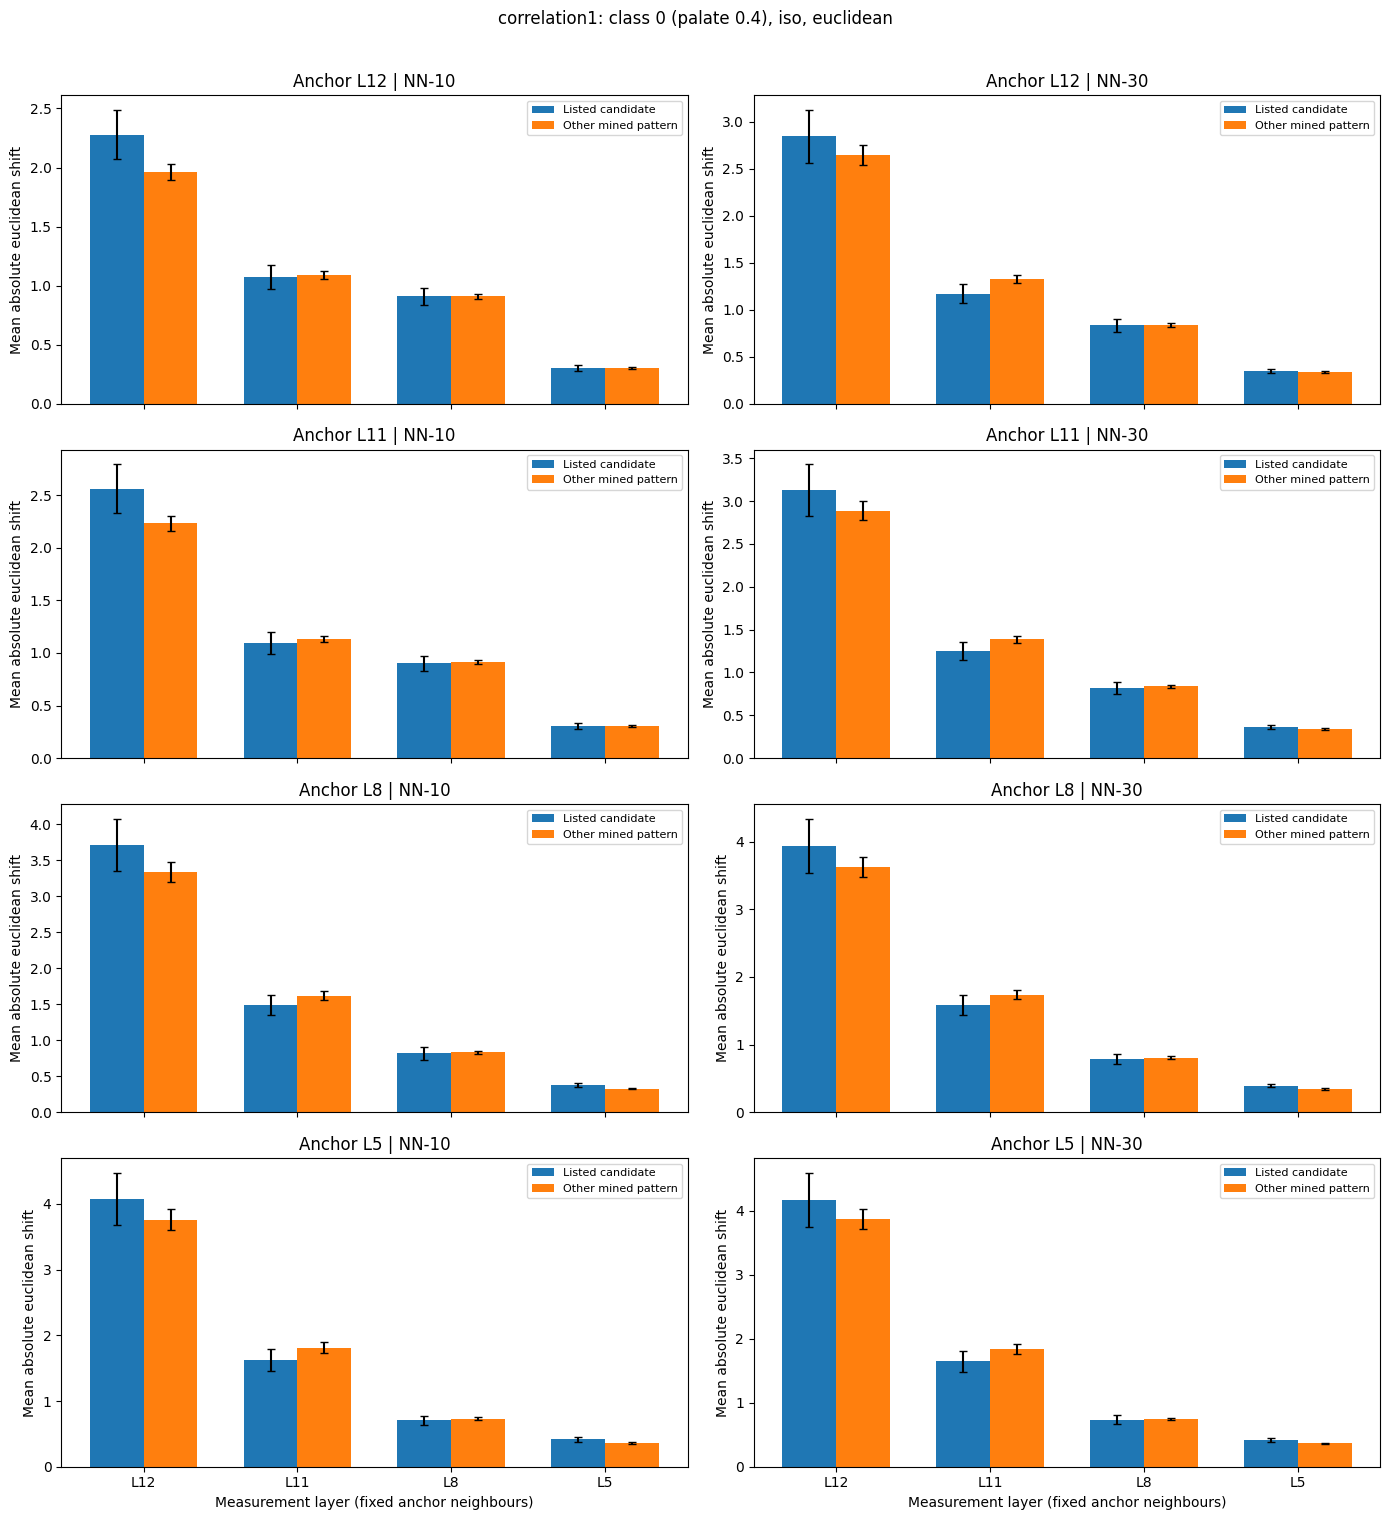

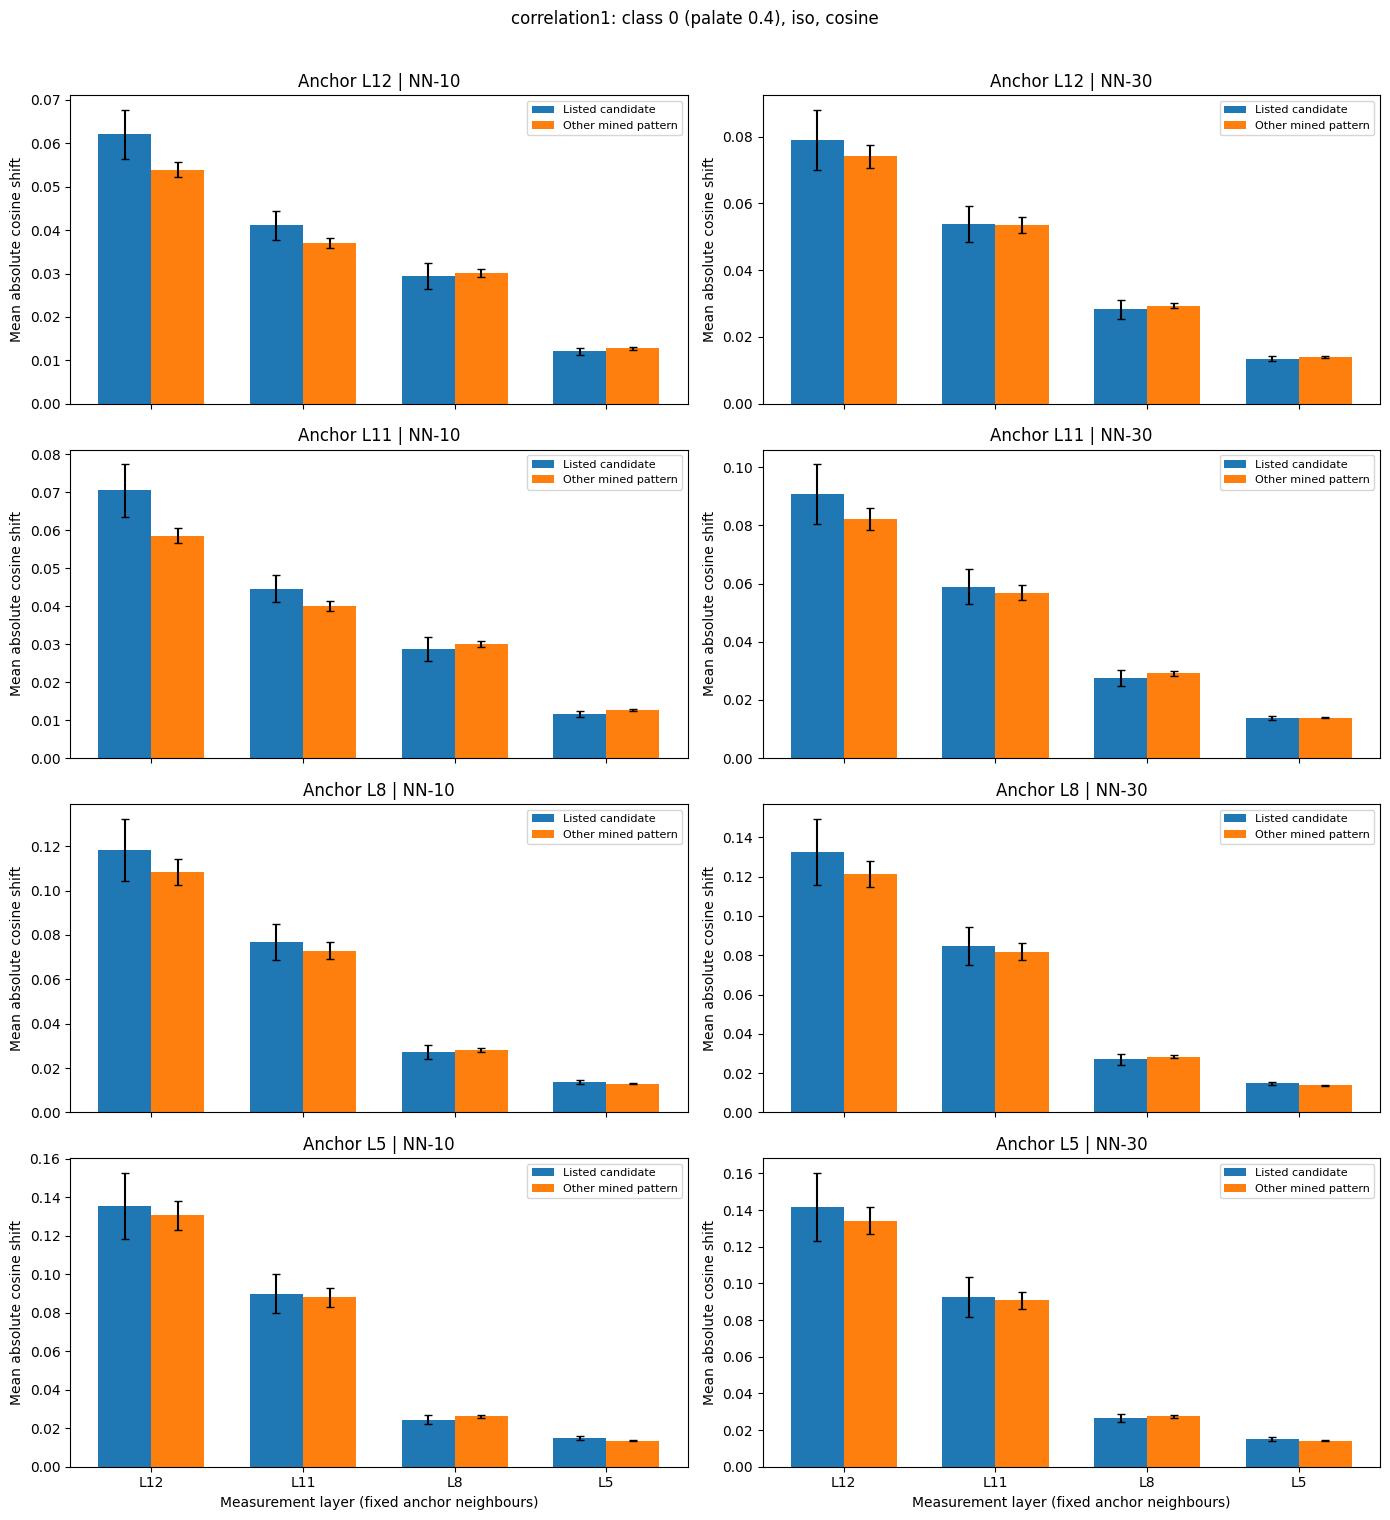

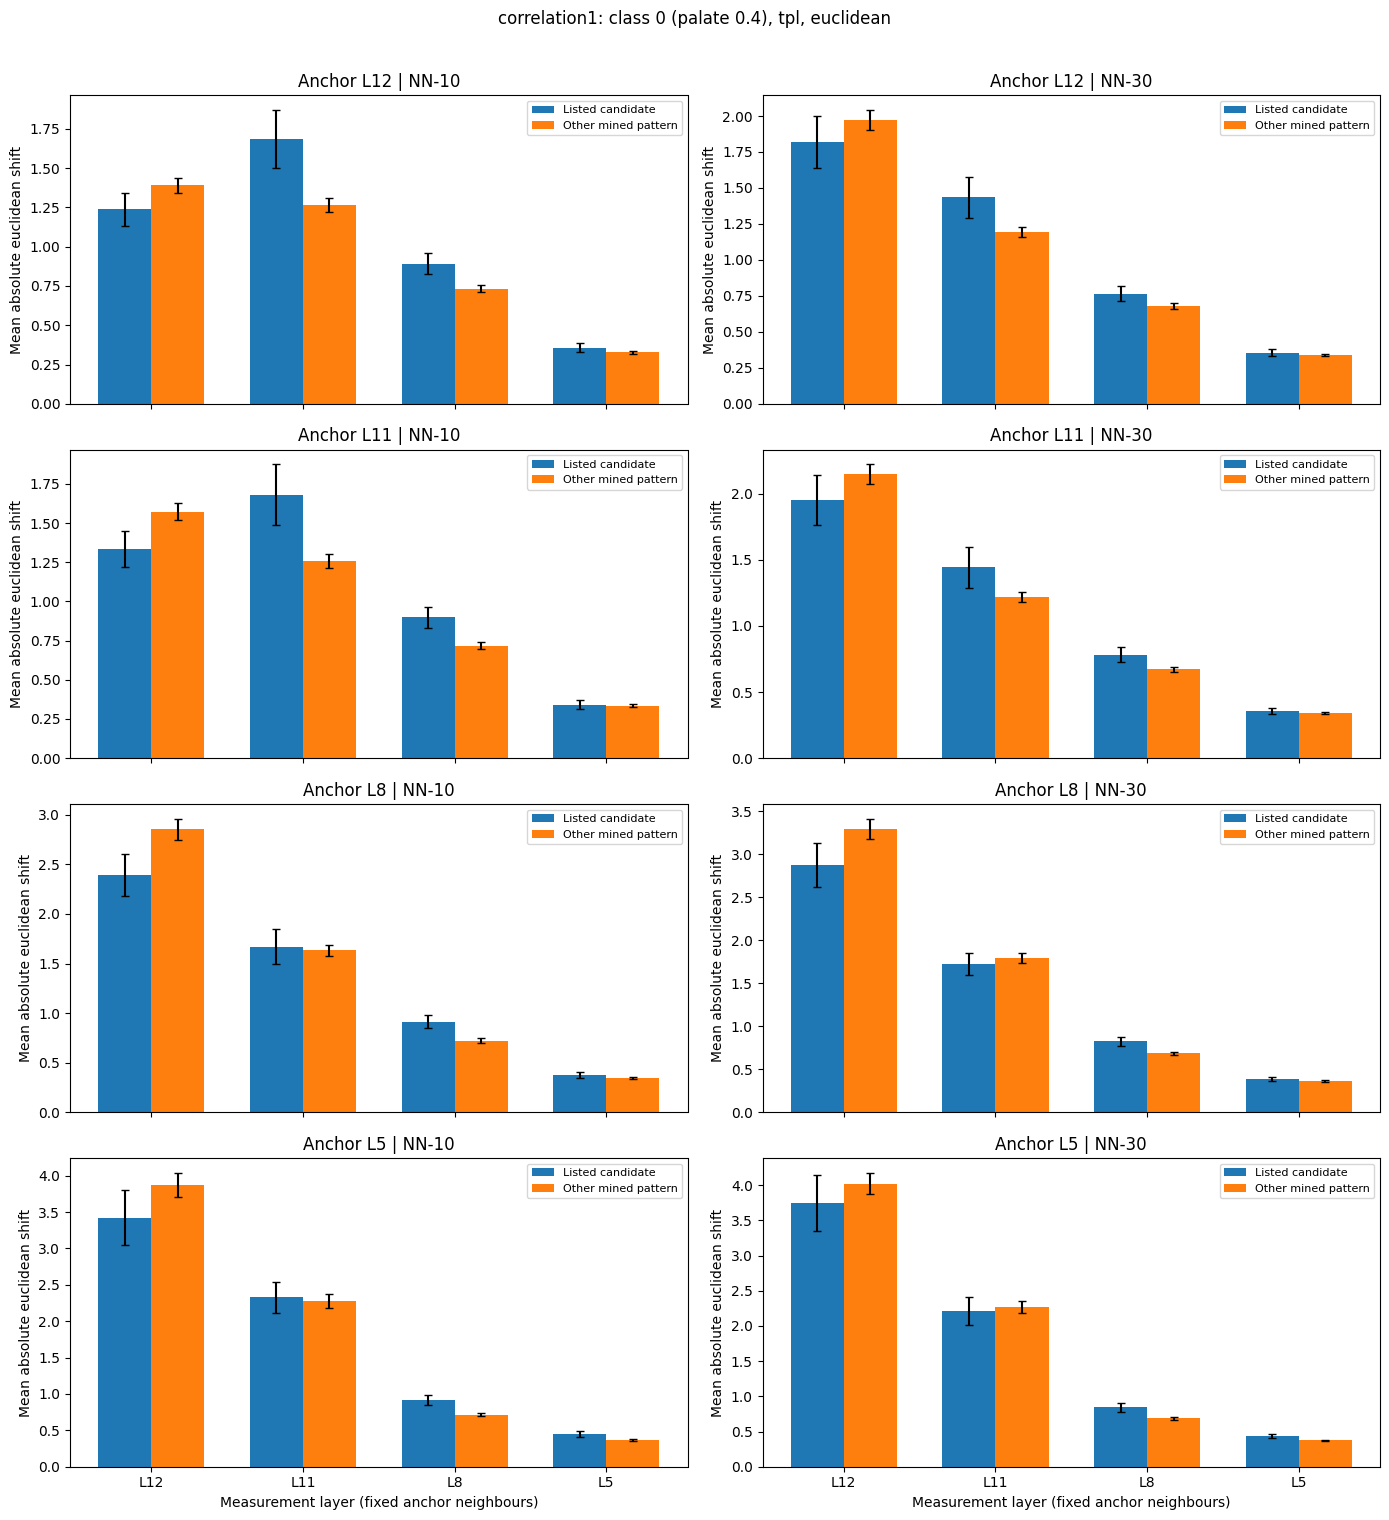

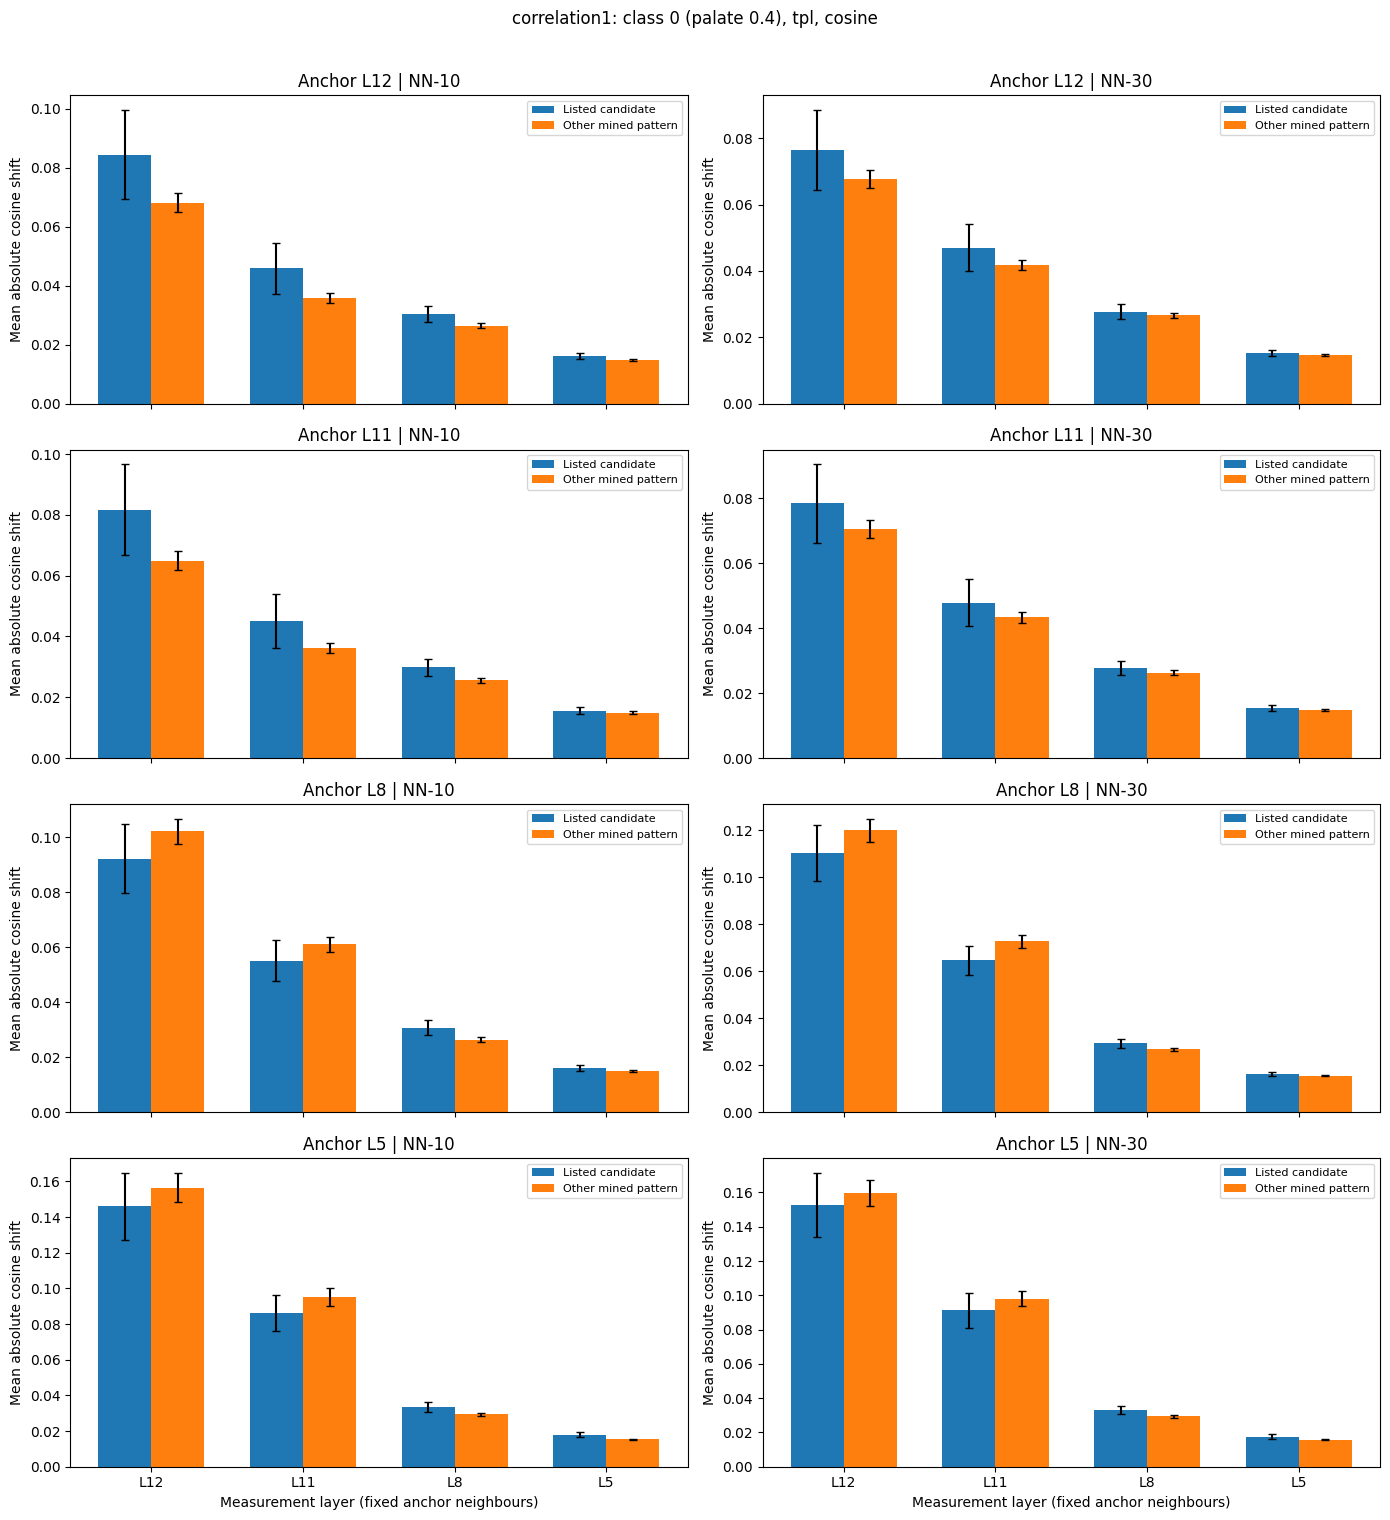

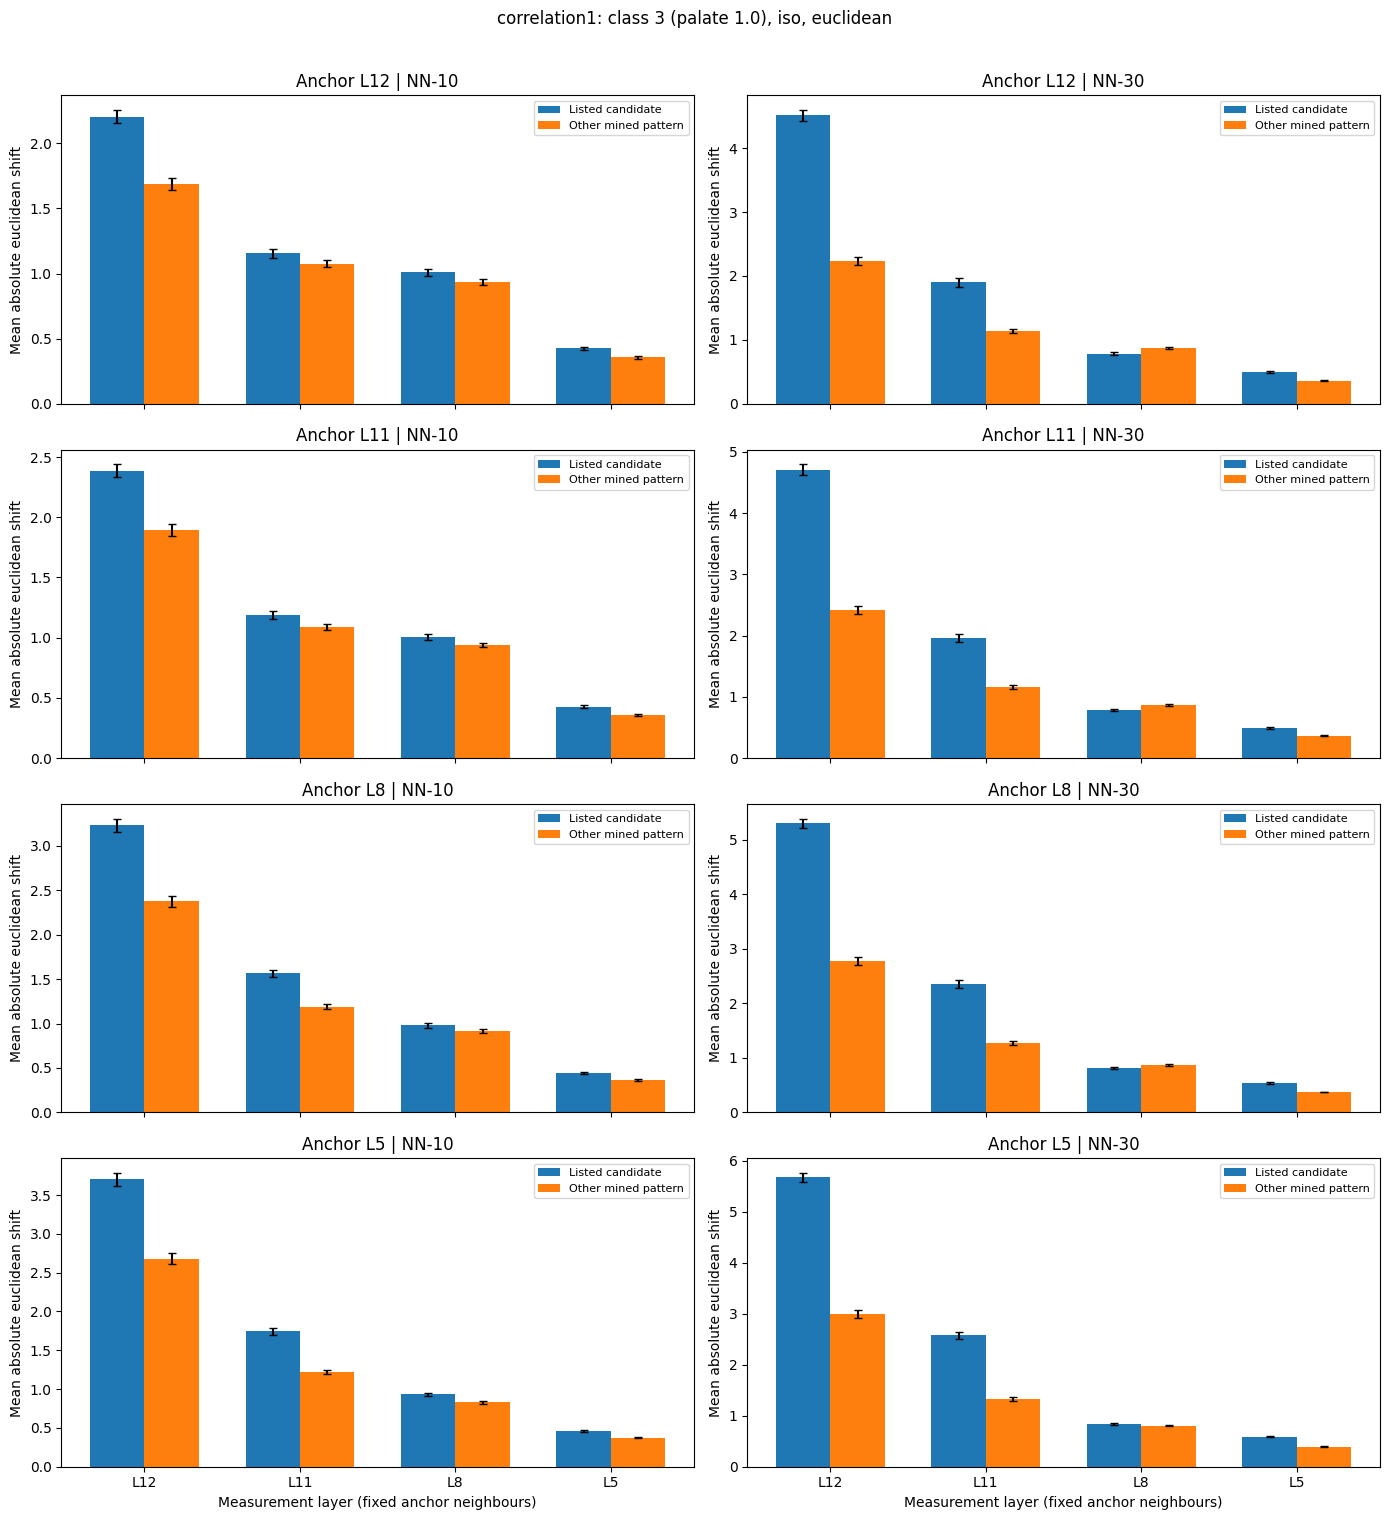

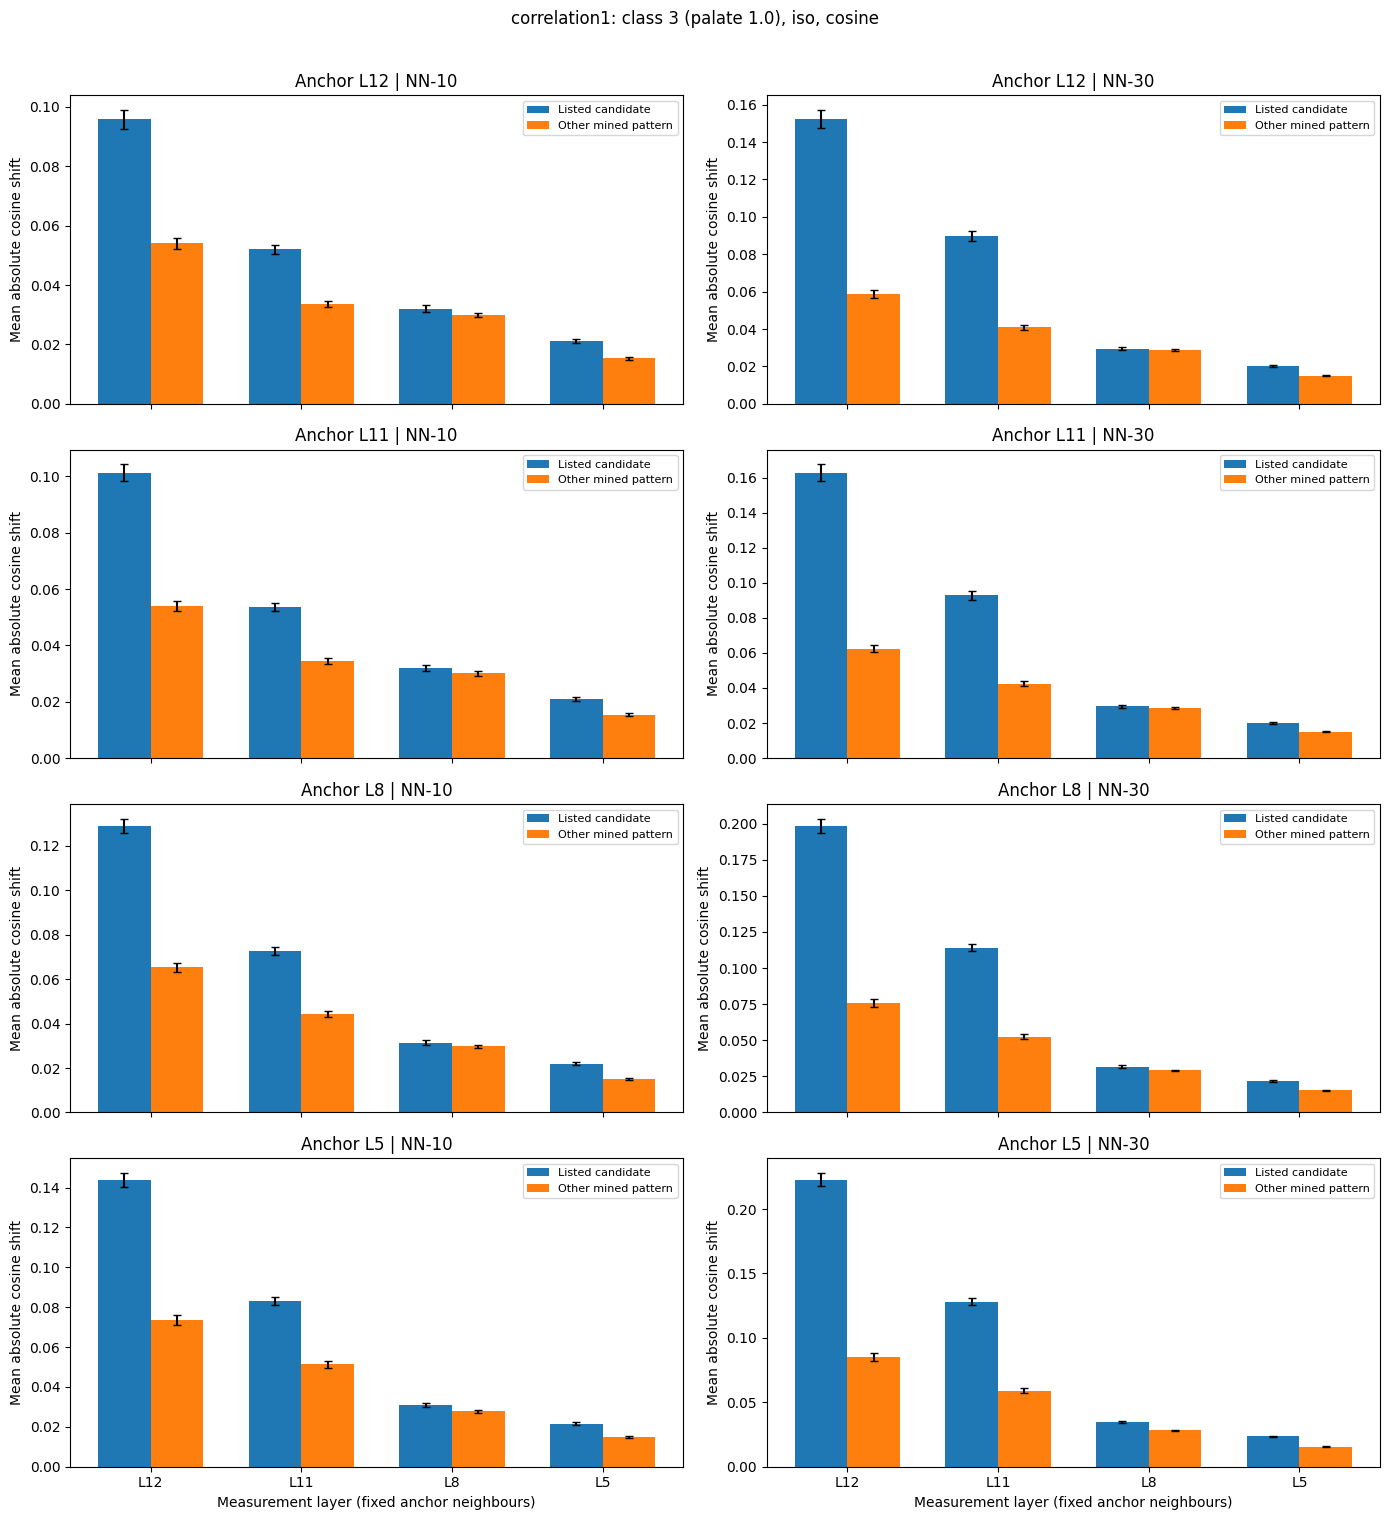

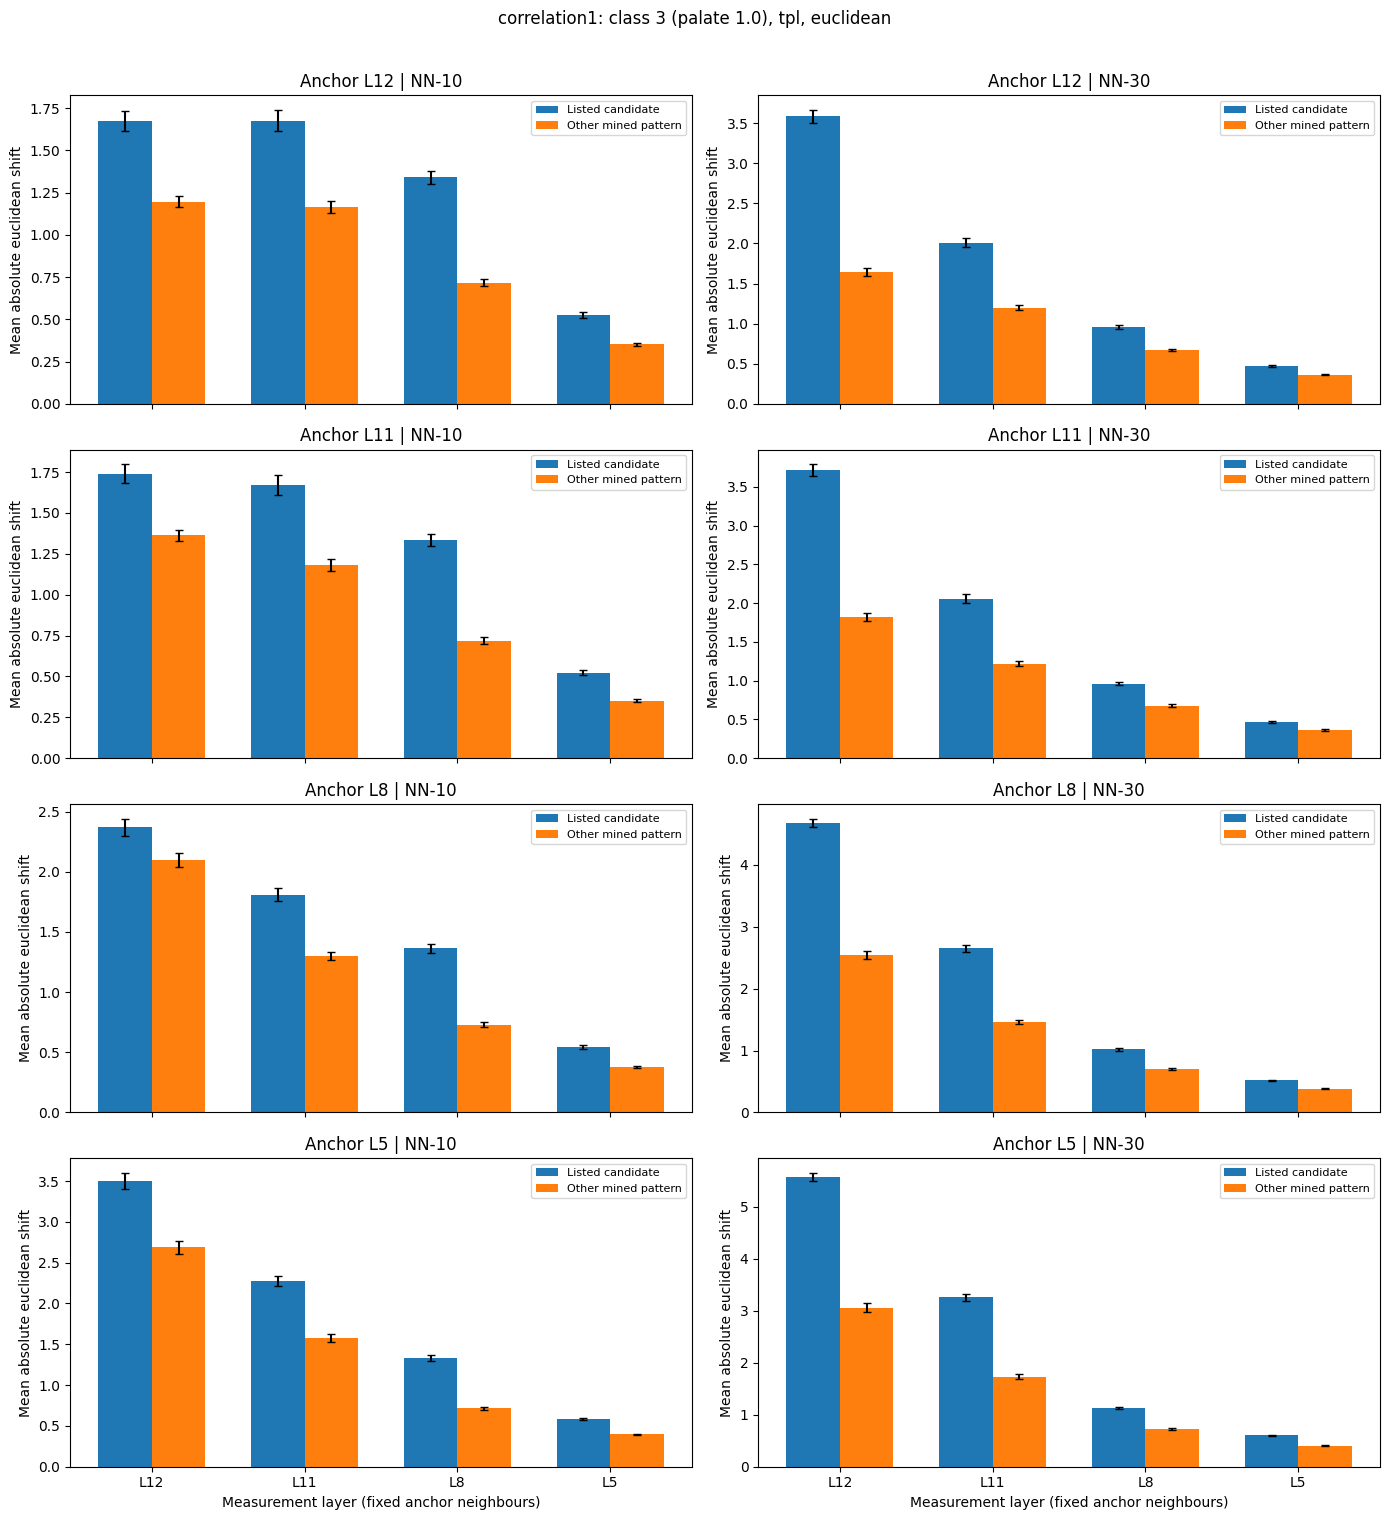

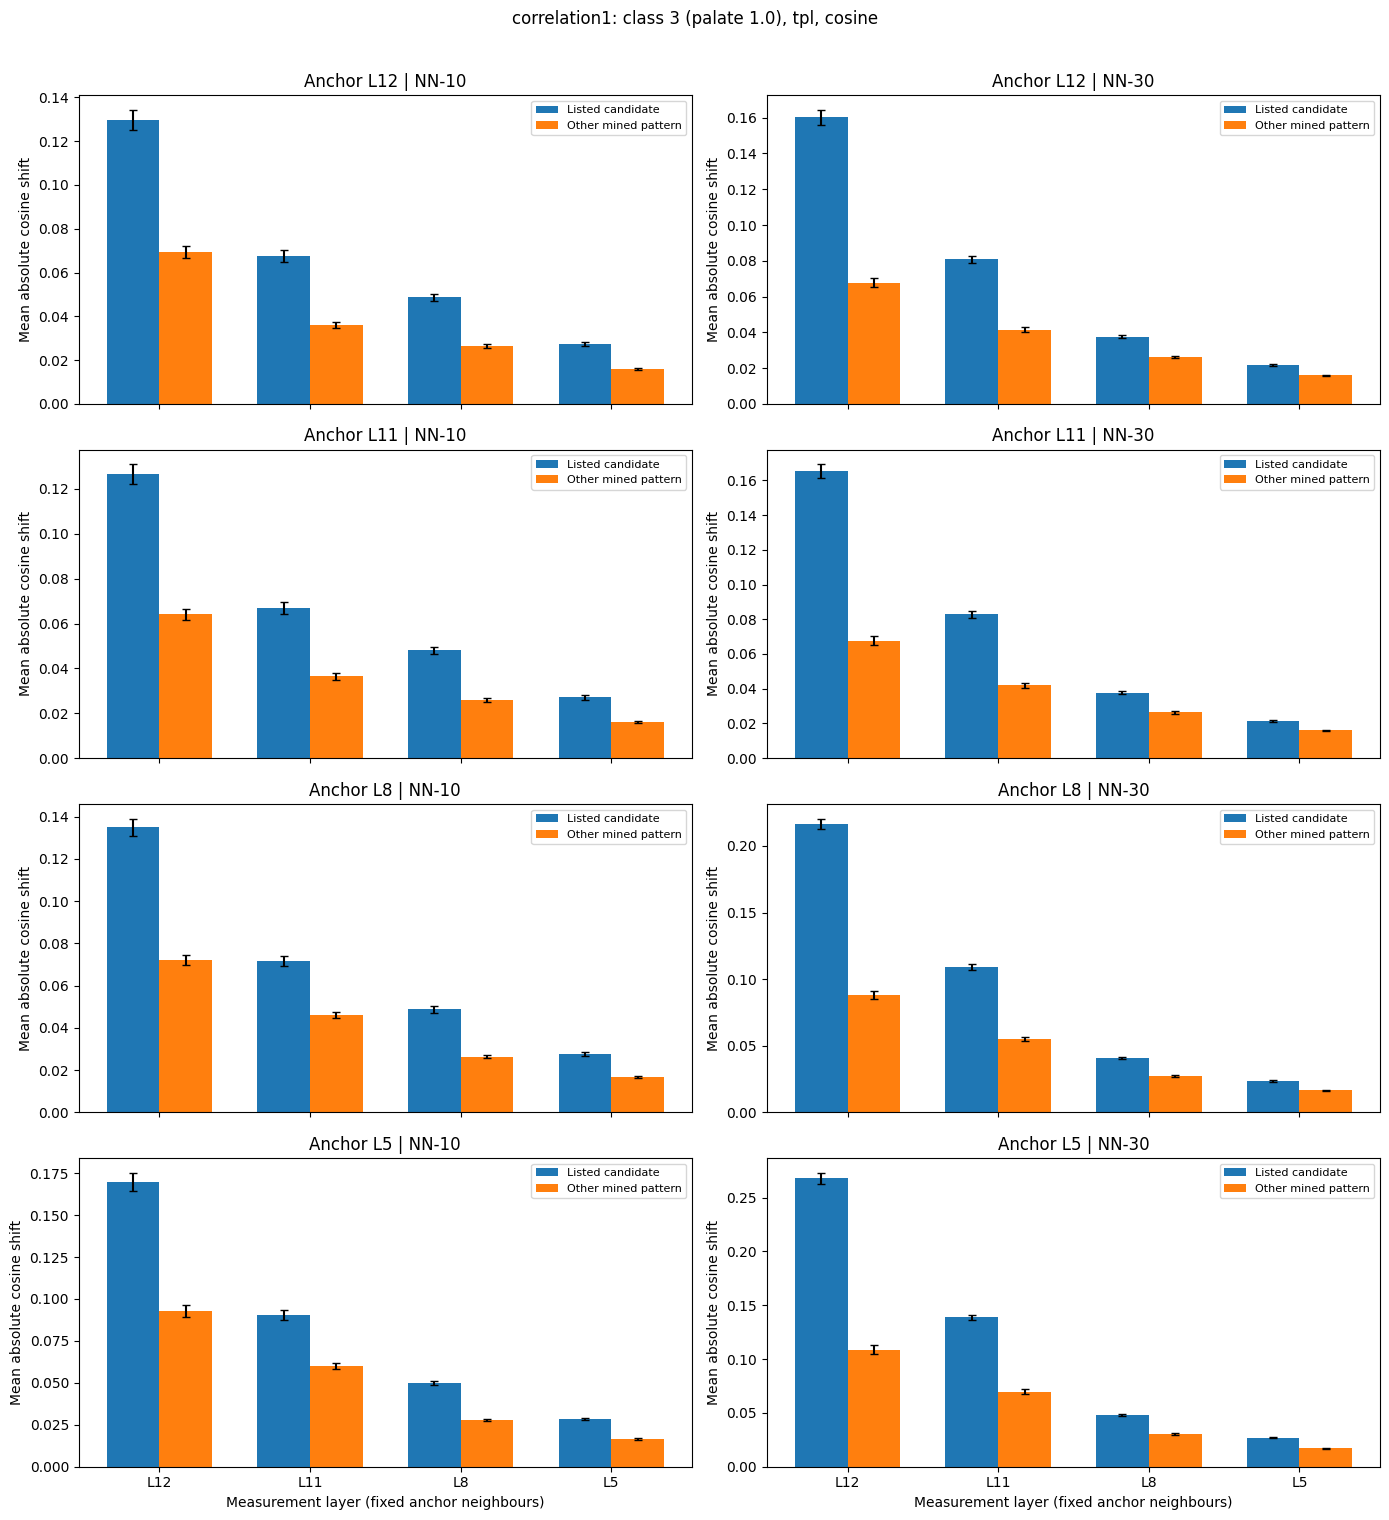

In [38]:
def plot_anchor_shortcut_means(summary, predicted_class, context="iso", metric="euclidean"):
    """Compare pattern-group means across measured layers with fixed FT anchor neighbours."""
    if predicted_class not in SHORTCUT_CANDIDATES_BY_CLASS:
        raise ValueError("No class-specific candidate list exists for this predicted class")
    if context not in NN_CONTEXTS or metric not in ("euclidean", "cosine"):
        raise ValueError("Invalid context or distance metric")

    mean_col = f"mean_delta_{metric}"
    sem_col = f"sem_delta_{metric}"
    fig, axes = plt.subplots(len(ANCHOR_LAYERS), len(NN_K_VALUES), figsize=(14, 15),
                             sharex=True, squeeze=False)
    x = np.arange(len(ANCHOR_LAYERS))
    bar_width = 0.35

    for i, anchor_layer in enumerate(ANCHOR_LAYERS):
        for j, k in enumerate(NN_K_VALUES):
            ax = axes[i, j]
            selected = summary.loc[
                (summary["predicted_class"] == predicted_class)
                & (summary["context"] == context)
                & (summary["anchor_layer"] == anchor_layer)
                & (summary["k"] == k)
            ]
            for offset, group, label in (
                (-bar_width / 2, "listed_candidate", "Listed candidate"),
                (+bar_width / 2, "other_pattern", "Other mined pattern"),
            ):
                group_rows = selected.loc[selected["group"] == group].set_index("layer")
                group_rows = group_rows.reindex(ANCHOR_LAYERS)
                ax.bar(
                    x + offset, group_rows[mean_col].to_numpy(dtype=float), bar_width,
                    yerr=group_rows[sem_col].fillna(0).to_numpy(dtype=float),
                    capsize=3, label=label,
                )
            ax.set_title(f"Anchor L{anchor_layer} | NN-{k}")
            ax.set_ylabel(f"Mean absolute {metric} shift")
            ax.set_xticks(x, [f"L{layer}" for layer in ANCHOR_LAYERS])
            ax.legend(fontsize=8)
            if i == len(ANCHOR_LAYERS) - 1:
                ax.set_xlabel("Measurement layer (fixed anchor neighbours)")

    fig.suptitle(
        f"{EXPERIMENT}: class {predicted_class} (palate {ID_TO_RATING[predicted_class]:.1f}), "
        f"{context}, {metric}", y=1.01
    )
    fig.tight_layout()
    plt.show()
    return fig


# NN-10 and NN-30 appear side-by-side for each anchor in both contexts and classes.
# Error bars are SEM across mined patterns; a single-pattern group has undefined SEM.
for class_id in SHORTCUT_CANDIDATES_BY_CLASS:
    for context in NN_CONTEXTS:
        for metric in ("euclidean", "cosine"):
            plot_anchor_shortcut_means(anchor_shortcut_summary_df, class_id, context, metric)


In [39]:
# Top 30 patterns: anchor L12, measurement L12, templated context.
for class_id in (0, 3):
    for k in (10, 30):
        for metric in ("euclidean", "cosine"):
            delta_col = f"mean_abs_{metric}_shift"

            top30 = (
                anchor_shortcut_pattern_df.query(
                    "predicted_class == @class_id and "
                    "anchor_layer == 12 and "
                    "layer == 12 and "
                    "k == @k and "
                    "context == 'tpl'"
                )
                .sort_values(delta_col, ascending=False)
                .head(30)
            )

            print(f"Class {class_id} | NN-{k} | {metric} delta")
            display(top30[
                ["ordered_tokens", "group", "support",
                 "mean_abs_euclidean_shift", "mean_abs_cosine_shift"]
            ])

Class 0 | NN-10 | euclidean delta


,ordered_tokens,group,support,mean_abs_euclidean_shift,mean_abs_cosine_shift
13408,"[great, .]",other_pattern,0.020548,4.667437,0.344036
3360,[cloudy],other_pattern,0.023973,4.382544,0.101636
7392,"[., very, thin]",other_pattern,0.071918,3.750226,0.066797
8928,"[good, .]",other_pattern,0.037671,3.718892,0.331134
2784,[terrible],other_pattern,0.023973,3.681373,0.082852
18016,"[watery, and, .]",other_pattern,0.020548,3.552445,0.053818
7136,"[very, watery]",other_pattern,0.051370,3.528107,0.052518
7648,"[very, watery, mouth]",other_pattern,0.020548,3.515571,0.051921
20128,"[decent, .]",other_pattern,0.034247,3.459617,0.358189
6816,"[aroma, ., watery, thin]",other_pattern,0.023973,3.457603,0.045001


Class 0 | NN-10 | cosine delta


,ordered_tokens,group,support,mean_abs_euclidean_shift,mean_abs_cosine_shift
20128,"[decent, .]",other_pattern,0.034247,3.459617,0.358189
13408,"[great, .]",other_pattern,0.020548,4.667437,0.344036
19232,"[hop, .]",other_pattern,0.041096,2.690552,0.343577
12448,"[creamy, .]",other_pattern,0.041096,2.920010,0.336150
20512,"[grain, .]",listed_candidate,0.020548,2.415237,0.331787
8928,"[good, .]",other_pattern,0.037671,3.718892,0.331134
15840,"[smooth, .]",other_pattern,0.023973,3.436026,0.316120
18720,"[sk, ##unk, .]",listed_candidate,0.020548,1.213673,0.295610
14496,"[faint, .]",listed_candidate,0.051370,1.614326,0.291734
8480,"[too, thin, .]",other_pattern,0.030822,0.748516,0.228235


Class 0 | NN-30 | euclidean delta


...

,ordered_tokens,group,support,mean_abs_euclidean_shift,mean_abs_cosine_shift
42336,"[huge, .]",other_pattern,0.013011,4.996534,0.379744
57888,"[incredible, .]",listed_candidate,0.035316,5.340828,0.375192
39776,"[fantastic, .]",listed_candidate,0.044610,5.514317,0.370715
37216,"[perfect, .]",listed_candidate,0.104089,4.847840,0.370220
44768,"[citrus, .]",other_pattern,0.024164,2.839170,0.360951
52960,"[outstanding, .]",listed_candidate,0.014870,4.861477,0.360844
58656,"[amazing, .]",listed_candidate,0.063197,5.401166,0.355001
42656,"[stout, .]",other_pattern,0.024164,2.560883,0.354360
56672,"[wonderful, .]",listed_candidate,0.046468,5.301795,0.353780
38816,"[great, .]",listed_candidate,0.065056,4.667437,0.344036


Class 3 | NN-30 | euclidean delta


,ordered_tokens,group,support,mean_abs_euclidean_shift,mean_abs_cosine_shift
46945,"[exceptional, perfect]",listed_candidate,0.011152,6.376853,0.272535
58849,"[amazing, perfect]",listed_candidate,0.018587,6.175740,0.258644
57057,"[wonderful, perfect]",listed_candidate,0.024164,6.154359,0.256438
40161,"[fantastic, perfect]",listed_candidate,0.013011,6.061418,0.254736
38881,"[perfect, great]",listed_candidate,0.027881,5.802225,0.253830
53409,"[awesome, wonderful]",listed_candidate,0.014870,5.693147,0.247460
53601,"[awesome, perfect]",listed_candidate,0.013011,5.598268,0.242297
53921,"[awesome, wonderful, .]",listed_candidate,0.011152,5.576629,0.249646
24481,[beautiful],listed_candidate,0.046468,5.556435,0.170313
27169,[incredible],listed_candidate,0.053903,5.525909,0.238739


Class 3 | NN-30 | cosine delta


,ordered_tokens,group,support,mean_abs_euclidean_shift,mean_abs_cosine_shift
44769,"[citrus, .]",other_pattern,0.024164,2.300931,0.344520
42657,"[stout, .]",other_pattern,0.024164,1.921004,0.333780
54177,"[hop, .]",other_pattern,0.044610,2.354770,0.333644
40993,"[good, .]",listed_candidate,0.026022,2.812524,0.322233
60193,"[floral, .]",listed_candidate,0.018587,1.580509,0.319000
46945,"[exceptional, perfect]",listed_candidate,0.011152,6.376853,0.272535
50529,"[sweet, .]",other_pattern,0.014870,1.873238,0.268339
63713,"[hazy, .]",other_pattern,0.018587,0.953004,0.264621
54689,"[aroma, hop, .]",other_pattern,0.020446,0.836133,0.259593
58849,"[amazing, perfect]",listed_candidate,0.018587,6.175740,0.258644


In [40]:
# import pandas as pd

# for metric in ("euclidean", "cosine"):
#     top30_results = []
#     delta_col = f"mean_abs_{metric}_shift"

#     for class_id in (0, 3):
#         for k in (10, 30):
#             top30 = (
#                 anchor_shortcut_pattern_df.query(
#                     "predicted_class == @class_id and "
#                     "anchor_layer == 12 and "
#                     "layer == 12 and "
#                     "k == @k and "
#                     "context == 'tpl'"
#                 )
#                 .sort_values(delta_col, ascending=False)
#                 .head(30)
#                 .copy()
#             )

#             # Convert FT-selected neighbour IDs to WordPiece tokens.
#             top30["neighbours"] = top30["ft_anchor_nn_token_ids"].apply(
#                 tokenizer.convert_ids_to_tokens
#             )

#             top30["rank"] = range(1, len(top30) + 1)
#             top30_results.append(top30)

#     top30_export = pd.concat(top30_results, ignore_index=True)

#     top30_export = top30_export[
#         [
#             "predicted_class",
#             "k",
#             "rank",
#             "ordered_tokens",
#             "neighbours",
#             delta_col,
#         ]
#     ]

#     filename = f"beer_top30_{metric}_layer12_correlation.csv"
#     top30_export.to_csv(filename, index=False)

#     print(f"Saved: {filename}")

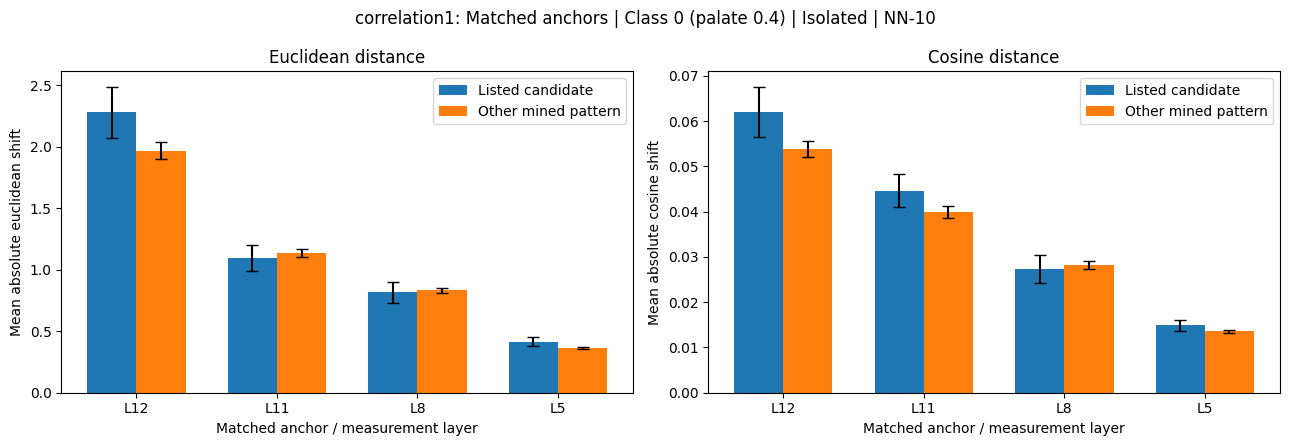

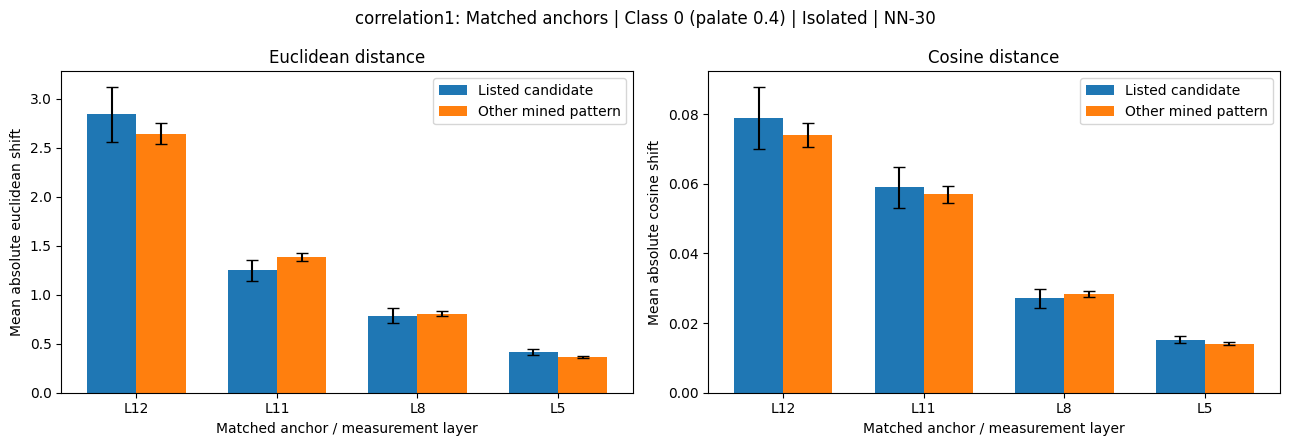

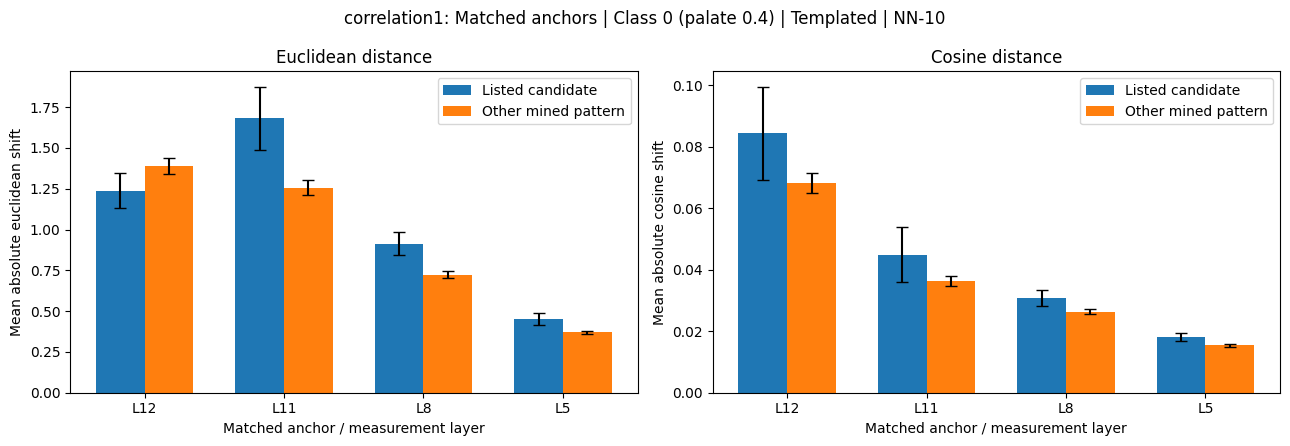

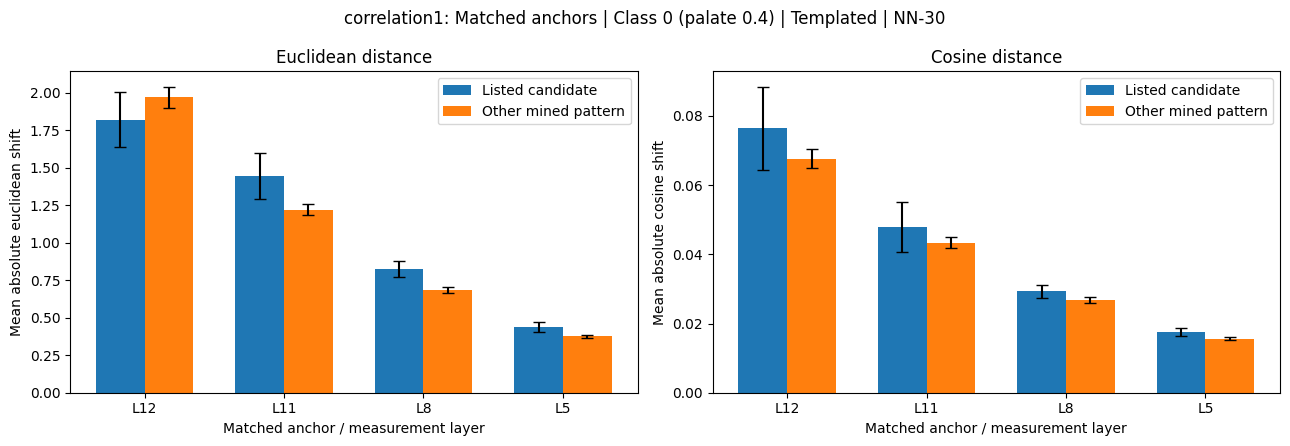

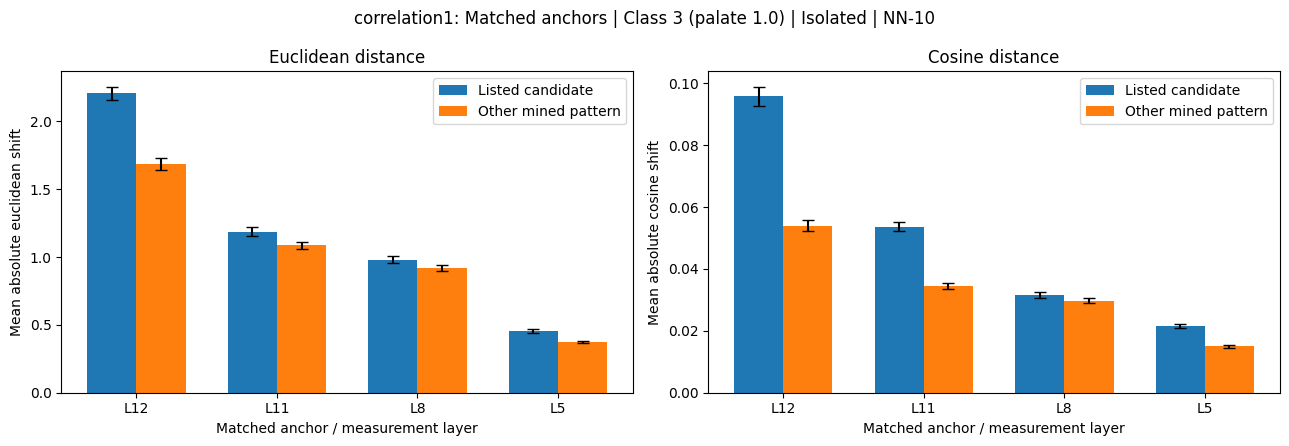

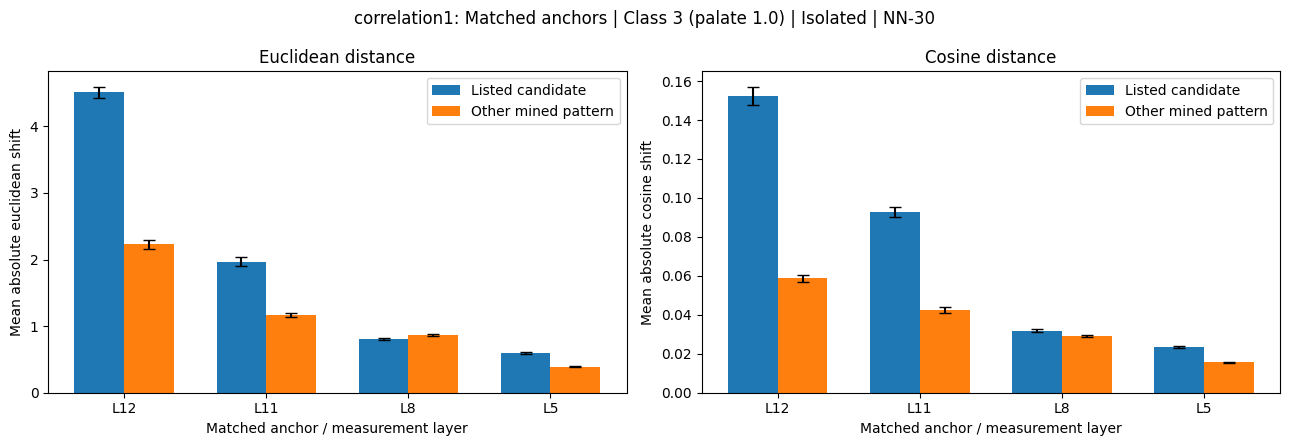

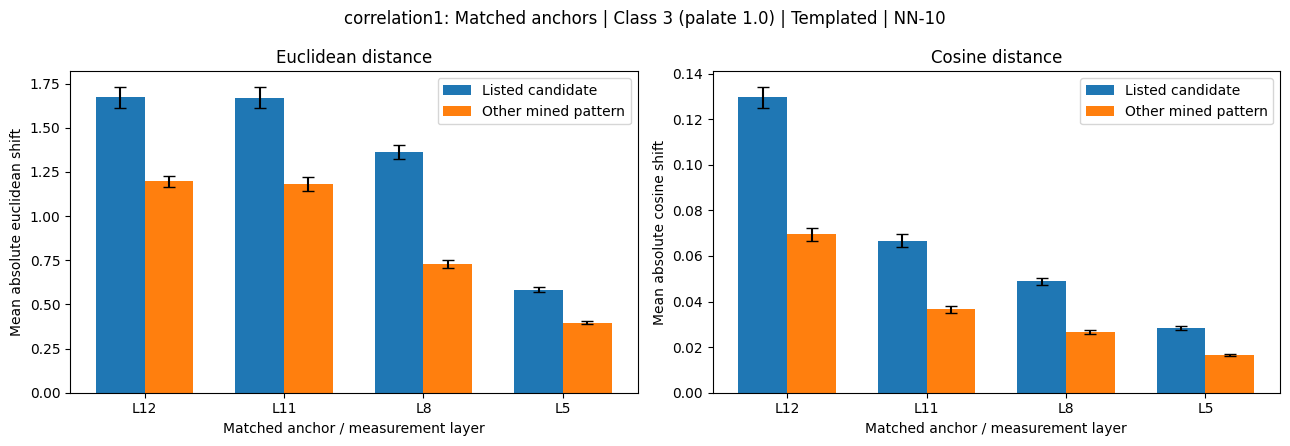

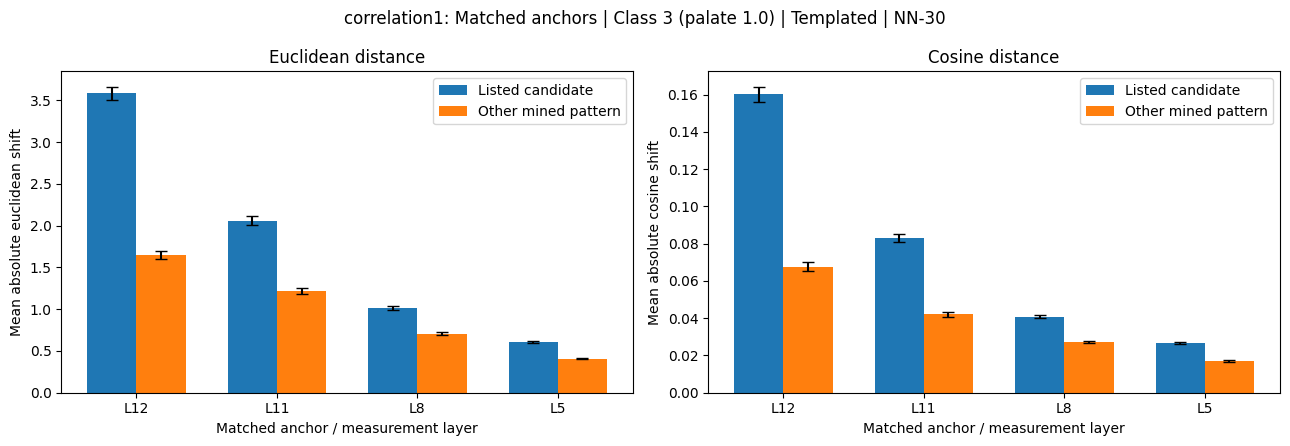

,predicted_class,rating,context,k,anchor_layer,layer,group,n_patterns,mean_delta_euclidean,sem_delta_euclidean,mean_delta_cosine,sem_delta_cosine
30,0,0.4,iso,10,12,12,listed_candidate,30,2.279158,0.207862,0.062054,0.005593
31,0,0.4,iso,10,12,12,other_pattern,295,1.965287,0.068106,0.053887,0.001767
20,0,0.4,iso,10,11,11,listed_candidate,30,1.095817,0.106396,0.044656,0.003650
21,0,0.4,iso,10,11,11,other_pattern,295,1.133277,0.031141,0.039970,0.001344
10,0,0.4,iso,10,8,8,listed_candidate,30,0.817925,0.085031,0.027317,0.003104
...,...,...,...,...,...,...,...,...,...,...,...,...
245,3,1.0,tpl,30,11,11,other_pattern,448,1.219483,0.034195,0.042051,0.001431
234,3,1.0,tpl,30,8,8,listed_candidate,271,1.017237,0.021826,0.040916,0.000867
235,3,1.0,tpl,30,8,8,other_pattern,448,0.704055,0.017090,0.027132,0.000700
224,3,1.0,tpl,30,5,5,listed_candidate,271,0.603238,0.011884,0.026915,0.000547


In [42]:

# ============================================================
# Experiment 3: Matched-anchor summary
# L12->L12, L11->L11, L8->L8, L5->L5
# ============================================================

matched_anchor_summary_df = anchor_shortcut_summary_df.loc[
    anchor_shortcut_summary_df["anchor_layer"]
    == anchor_shortcut_summary_df["layer"]
].copy()


def plot_matched_anchor_summary(
    summary,
    predicted_class,
    context="iso",
    k=10,
):
    """Plot matched-anchor shifts with SEM across patterns."""

    selected = summary.loc[
        (summary["predicted_class"] == predicted_class)
        & (summary["context"] == context)
        & (summary["k"] == k)
    ]

    layer_order = list(ANCHOR_LAYERS)
    x = np.arange(len(layer_order))
    width = 0.35

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

    for ax, metric in zip(axes, ("euclidean", "cosine")):

        mean_col = f"mean_delta_{metric}"
        sem_col = f"sem_delta_{metric}"

        for offset, group, label in (
            (-width / 2, "listed_candidate", "Listed candidate"),
            (+width / 2, "other_pattern", "Other mined pattern"),
        ):

            group_rows = (
                selected.loc[selected["group"] == group]
                .set_index("anchor_layer")
                .reindex(layer_order)
            )

            means = group_rows[mean_col].to_numpy(dtype=float)
            sems = group_rows[sem_col].fillna(0).to_numpy(dtype=float)

            valid = np.isfinite(means)

            ax.bar(
                (x + offset)[valid],
                means[valid],
                width,
                yerr=sems[valid],
                capsize=4,
                label=label,
            )

        ax.set_xticks(x, [f"L{layer}" for layer in layer_order])
        ax.set_xlabel("Matched anchor / measurement layer")
        ax.set_ylabel(f"Mean absolute {metric} shift")
        ax.set_title(f"{metric.capitalize()} distance")
        ax.legend()

    context_name = "Isolated" if context == "iso" else "Templated"

    fig.suptitle(
        f"{EXPERIMENT}: Matched anchors | "
        f"Class {predicted_class} "
        f"(palate {ID_TO_RATING[predicted_class]:.1f}) | "
        f"{context_name} | NN-{k}"
    )

    fig.tight_layout()
    plt.show()

    return fig


for class_id in SHORTCUT_CANDIDATES_BY_CLASS:
    for context in NN_CONTEXTS:
        for k in NN_K_VALUES:
            plot_matched_anchor_summary(
                matched_anchor_summary_df,
                predicted_class=class_id,
                context=context,
                k=k,
            )

display(
    matched_anchor_summary_df.sort_values(
        ["predicted_class", "context", "k", "anchor_layer"],
        ascending=[True, True, True, False],
    )
)
